In [1]:
import pandas as pd 
import numpy as np 
import scanpy as sc
import pycisTopic
pycisTopic.__version__

import os
out_dir = "scenic_hm_outs"
os.makedirs(out_dir, exist_ok = True)

/home/rsun@ZHANGroup.local/anaconda3/envs/scenicplus/lib/python3.11/site-packages/pycisTopic/__init__.py:3: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import DistributionNotFound, get_distribution


## 概述

在这一版中，尝试取消或者降低QC标准，保留更多细胞，不分细胞类型保存cistopic object，直接保留整个海马神经元的结果进行后续调控分析，用RSS等结果来实现差异分析

## get cell anno 

In [3]:
cell_data = pd.read_csv('/home/rsun@ZHANGroup.local/sly_data/grn_momics/scenic_noqc_outs/cell_data.csv', index_col = 0)
cell_data.head()

,leiden,eco,species,sample
AAACAGCCAATCCCTT-1-CYHM,1,eco,CY,CYHM
AAACAGCCACAGGAAT-1-CYHM,2,eco,CY,CYHM
AAACAGCCAGCAGGTA-1-CYHM,1,eco,CY,CYHM
AAACAGCCAGCATGAG-1-CYHM,1,eco,CY,CYHM
AAACATGCAAGGACCA-1-CYHM,7,eco,CY,CYHM


## get pseudobulk profiles from cell annotations

In [6]:
chromsizes = pd.read_table(
    "http://hgdownload.cse.ucsc.edu/goldenPath/mm10/bigZips/mm10.chrom.sizes",
    header = None,
    names = ["Chromosome", "End"]
)

chromsizes.insert(1, "Start", 0)
chromsizes.head()

fragments_dict = {'CYHM': '/home/rsun@ZHANGroup.local/sly_data/grn_momics/data/filter_fragments/cyhm_fragments/fragment.tsv.gz',
                'JTHM': '/home/rsun@ZHANGroup.local/sly_data/grn_momics/data/filter_fragments/jthm_fragments/fragment.tsv.gz',
                'QFHM': '/home/rsun@ZHANGroup.local/sly_data/grn_momics/data/filter_fragments/qfhm_fragments/fragment.tsv.gz',
                'MHM': '/home/rsun@ZHANGroup.local/sly_data/grn_momics/data/filter_fragments/mhm_fragments/fragment.tsv.gz',
                'THM': '/home/rsun@ZHANGroup.local/sly_data/grn_momics/data/filter_fragments/thm_fragments/fragment.tsv.gz'}

from pycisTopic.pseudobulk_peak_calling import export_pseudobulk
os.makedirs(os.path.join(out_dir, "consensus_peak_calling"), exist_ok = True)
os.makedirs(os.path.join(out_dir, "consensus_peak_calling/pseudobulk_bed_files"), exist_ok = True)
os.makedirs(os.path.join(out_dir, "consensus_peak_calling/pseudobulk_bw_files"), exist_ok = True)
os.makedirs(os.path.join(out_dir, 'temp'), exist_ok = True)

bw_paths, bed_paths = export_pseudobulk(
    input_data = cell_data,
    variable = "leiden",
    sample_id_col = "sample",
    chromsizes = chromsizes,
    bed_path = os.path.join(out_dir, "consensus_peak_calling/pseudobulk_bed_files"),
    bigwig_path = os.path.join(out_dir, "consensus_peak_calling/pseudobulk_bw_files"),
    path_to_fragments = fragments_dict,
    n_cpu = 10,
    normalize_bigwig = True,
    temp_dir = os.path.join(out_dir, 'temp'),
    split_pattern = '-'
)

2025-06-19 06:15:43,867 cisTopic     WARNING  Non-string values detected in leiden column. These will be converted to strings.
2025-06-19 06:15:43,934 cisTopic     INFO     Splitting fragments by cell type.
2025-06-19 06:16:49,144 cisTopic     INFO     generating bigwig files


/home/rsun@ZHANGroup.local/anaconda3/envs/scenicplus/lib/python3.11/site-packages/pycisTopic/__init__.py:3: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import DistributionNotFound, get_distribution
/home/rsun@ZHANGroup.local/anaconda3/envs/scenicplus/lib/python3.11/site-packages/pycisTopic/__init__.py:3: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import DistributionNotFound, get_distribution
/home/rsun@ZHANGroup.local/anaconda3/envs/scenicplus/lib/python3.11/site-packages/pycisTopic/__init__.py:3: UserWarning: pkg_resources is deprecated as an API. See ht

In [7]:
with open(os.path.join(out_dir, "consensus_peak_calling/bw_paths.tsv"), "wt") as f:
    for v in bw_paths:
        _ = f.write(f"{v}\t{bw_paths[v]}\n")

with open(os.path.join(out_dir, "consensus_peak_calling/bed_paths.tsv"), "wt") as f:
    for v in bed_paths:
        _ = f.write(f"{v}\t{bed_paths[v]}\n")

## infer consensus peaks using masc

In [8]:
bw_paths = {}
with open(os.path.join(out_dir, "consensus_peak_calling/bw_paths.tsv")) as f:
    for line in f:
        v, p = line.strip().split("\t")
        bw_paths.update({v: p})

bed_paths = {}
with open(os.path.join(out_dir, "consensus_peak_calling/bed_paths.tsv")) as f:
    for line in f:
        v, p = line.strip().split("\t")
        bed_paths.update({v: p})

from pycisTopic.pseudobulk_peak_calling import peak_calling
macs_path = "/home/rsun@ZHANGroup.local/anaconda3/envs/pyscenic/bin/macs2"

os.makedirs(os.path.join(out_dir, "consensus_peak_calling/MACS"), exist_ok = True)

narrow_peak_dict = peak_calling(
    macs_path = macs_path,
    bed_paths = bed_paths,
    outdir = os.path.join(os.path.join(out_dir, "consensus_peak_calling/MACS")),
    genome_size = 'hs',
    n_cpu = 10,
    input_format = 'BEDPE',
    shift = 73,
    ext_size = 146,
    keep_dup = 'all',
    q_value = 0.05,
    _temp_dir = None
)

2025-06-19 06:17:25,180	INFO worker.py:1724 -- Started a local Ray instance.
(pid=1475456) /home/rsun@ZHANGroup.local/anaconda3/envs/scenicplus/lib/python3.11/site-packages/pycisTopic/__init__.py:3: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
(pid=1475456)   from pkg_resources import DistributionNotFound, get_distribution


(macs_call_peak_ray pid=1475460) 2025-06-19 06:17:26,888 cisTopic     INFO     Calling peaks for 2 with /home/rsun@ZHANGroup.local/anaconda3/envs/pyscenic/bin/macs2 callpeak --treatment scenic_hm_outs/consensus_peak_calling/pseudobulk_bed_files/2.fragments.tsv.gz --name 2  --outdir scenic_hm_outs/consensus_peak_calling/MACS --format BEDPE --gsize hs --qvalue 0.05 --nomodel --shift 73 --extsize 146 --keep-dup all --call-summits --nolambda
(macs_call_peak_ray pid=1475461) 2025-06-19 06:18:17,265 cisTopic     INFO     6 done!
(macs_call_peak_ray pid=1475464) 2025-06-19 06:17:26,925 cisTopic     INFO     Calling peaks for 1 with /home/rsun@ZHANGroup.local/anaconda3/envs/pyscenic/bin/macs2 callpeak --treatment scenic_hm_outs/consensus_peak_calling/pseudobulk_bed_files/1.fragments.tsv.gz --name 1  --outdir scenic_hm_outs/consensus_peak_calling/MACS --format BEDPE --gsize hs --qvalue 0.05 --nomodel --shift 73 --extsize 146 --keep-dup all --call-summits --nolambda [repeated 9x across cluster] 

(pid=1475461) /home/rsun@ZHANGroup.local/anaconda3/envs/scenicplus/lib/python3.11/site-packages/pycisTopic/__init__.py:3: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81. [repeated 9x across cluster]
(pid=1475461)   from pkg_resources import DistributionNotFound, get_distribution [repeated 9x across cluster]


In [9]:
from pycisTopic.iterative_peak_calling import get_consensus_peaks
# Other param
peak_half_width=250
path_to_blacklist="/home/rsun@ZHANGroup.local/projects_list/pycisTopic-main/blacklist/mm10-blacklist.v2.bed"
# Get consensus peaks
consensus_peaks = get_consensus_peaks(
    narrow_peaks_dict = narrow_peak_dict,
    peak_half_width = peak_half_width,
    chromsizes = chromsizes,
    path_to_blacklist = path_to_blacklist)

consensus_peaks.to_bed(
    path = os.path.join(out_dir, "consensus_peak_calling/consensus_regions.bed"),
    keep =True,
    compression = 'infer',
    chain = False)

2025-06-19 06:20:06,502 cisTopic     INFO     Extending and merging peaks per class
2025-06-19 06:20:24,198 cisTopic     INFO     Normalizing peak scores
2025-06-19 06:20:24,697 cisTopic     INFO     Merging peaks
Warning! Start and End columns now have different dtypes: int64 and int32
2025-06-19 06:21:26,399 cisTopic     INFO     Done!


/home/rsun@ZHANGroup.local/anaconda3/envs/scenicplus/lib/python3.11/site-packages/pyranges/out.py:37: FutureWarning: Passing a set as an indexer is deprecated and will raise in a future version. Use a list instead.
  return pd.concat([outdf, df.get(noncanonical)], axis=1)
/home/rsun@ZHANGroup.local/anaconda3/envs/scenicplus/lib/python3.11/site-packages/pyranges/out.py:37: FutureWarning: Passing a set as an indexer is deprecated and will raise in a future version. Use a list instead.
  return pd.concat([outdf, df.get(noncanonical)], axis=1)
/home/rsun@ZHANGroup.local/anaconda3/envs/scenicplus/lib/python3.11/site-packages/pyranges/out.py:37: FutureWarning: Passing a set as an indexer is deprecated and will raise in a future version. Use a list instead.
  return pd.concat([outdf, df.get(noncanonical)], axis=1)
/home/rsun@ZHANGroup.local/anaconda3/envs/scenicplus/lib/python3.11/site-packages/pyranges/out.py:37: FutureWarning: Passing a set as an indexer is deprecated and will raise in a fu

## QC

In [11]:
!pycistopic tss gene_annotation_list | grep Mouse
!mkdir -p scenic_hm_outs/qc
!pycistopic tss get_tss \
    --output scenic_hm_outs/qc/tss.bed \
    --name "mmusculus_gene_ensembl" \
    --to-chrom-source ucsc \
    --ucsc mm10
!head scenic_hm_outs/qc/tss.bed | column -t

/home/rsun@ZHANGroup.local/anaconda3/envs/scenicplus/lib/python3.11/site-packages/pycisTopic/__init__.py:3: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import DistributionNotFound, get_distribution
mmurinus_gene_ensembl	Mouse Lemur genes (Mmur_3.0)
mmusculus_gene_ensembl	Mouse genes (GRCm39)
/home/rsun@ZHANGroup.local/anaconda3/envs/scenicplus/lib/python3.11/site-packages/pycisTopic/__init__.py:3: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import DistributionNotFound, get_distribution
- Get TSS annotation from Ensembl BioMart with the following settings:


In [13]:
## calculate qc metrics parallel 

regions_bed_filename = os.path.join(out_dir, "consensus_peak_calling/consensus_regions.bed")
tss_bed_filename = os.path.join(out_dir, "qc", "tss.bed")

pycistopic_qc_commands_filename = "pycistopic_qc_commands.txt"

# Create text file with all pycistopic qc command lines.
with open(pycistopic_qc_commands_filename, "w") as fh:
    for sample, fragment_filename in fragments_dict.items():
        print(
            "pycistopic qc",
            f"--fragments {fragment_filename}",
            f"--regions {regions_bed_filename}",
            f"--tss {tss_bed_filename}",
            f"--output {os.path.join(out_dir, 'qc')}/{sample}",
            sep=" ",
            file=fh,
        )

!cat pycistopic_qc_commands.txt | parallel -j 5 {}

Academic tradition requires you to cite works you base your article on.
If you use programs that use GNU Parallel to process data for an article in a
scientific publication, please cite:

  Tange, O. (2025, April 22). GNU Parallel 20250422 ('Tariffs').
  Zenodo. https://doi.org/10.5281/zenodo.15265748

This helps funding further development; AND IT WON'T COST YOU A CENT.
If you pay 10000 EUR you should feel free to use GNU Parallel without citing.

More about funding GNU Parallel and the citation notice:
https://www.gnu.org/software/parallel/parallel_design.html#citation-notice

To silence this citation notice: run 'parallel --citation' once.

/home/rsun@ZHANGroup.local/anaconda3/envs/scenicplus/lib/python3.11/site-packages/pycisTopic/__init__.py:3: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81

### qc plot

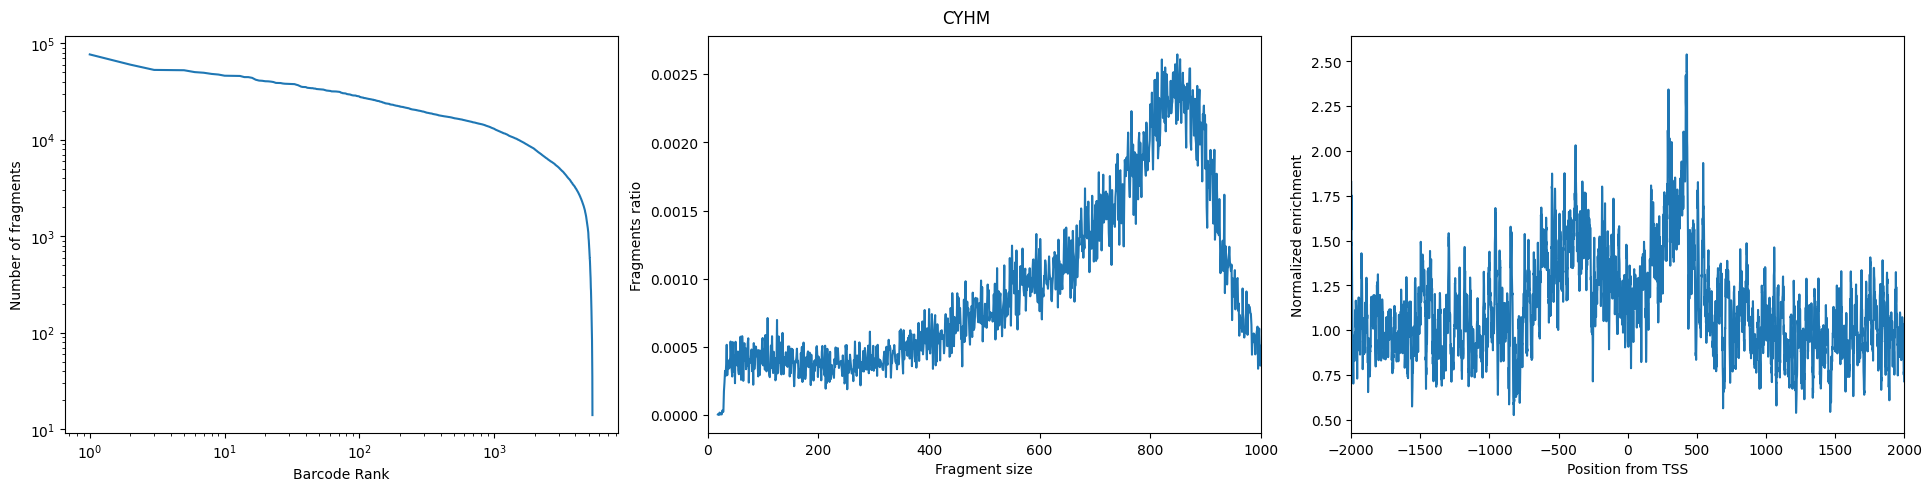

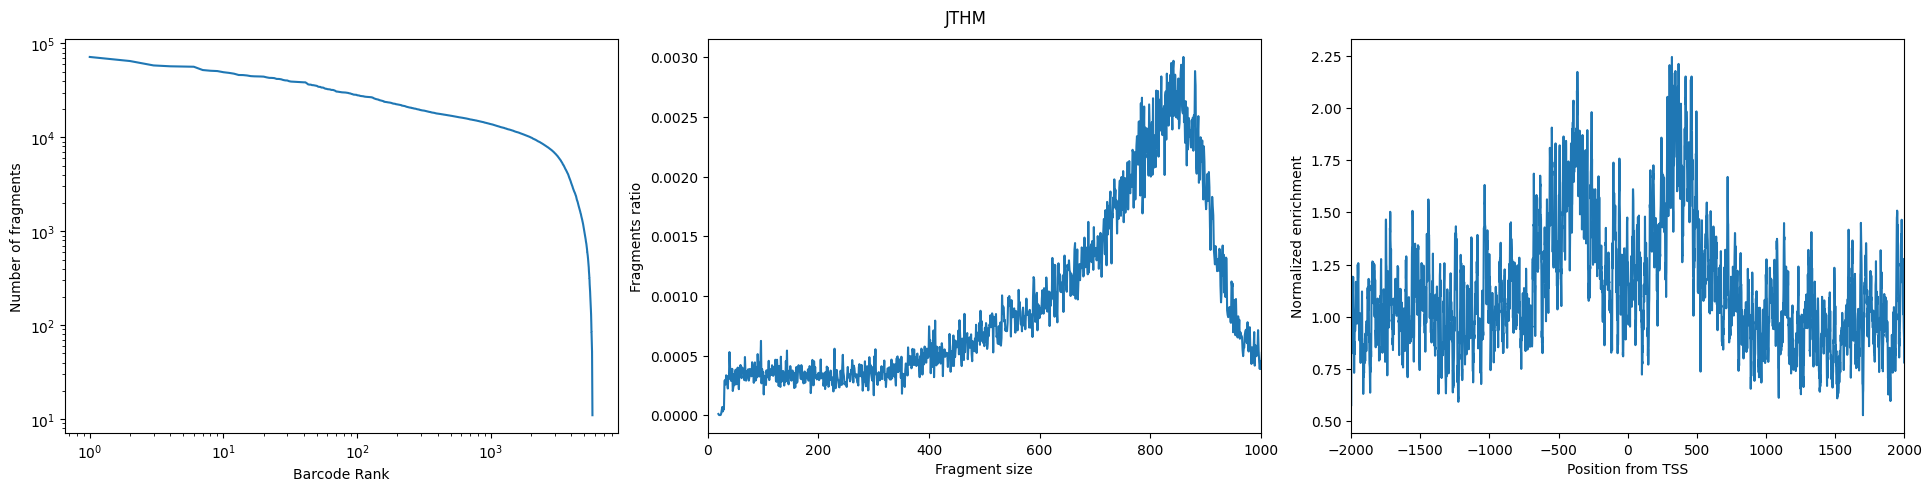

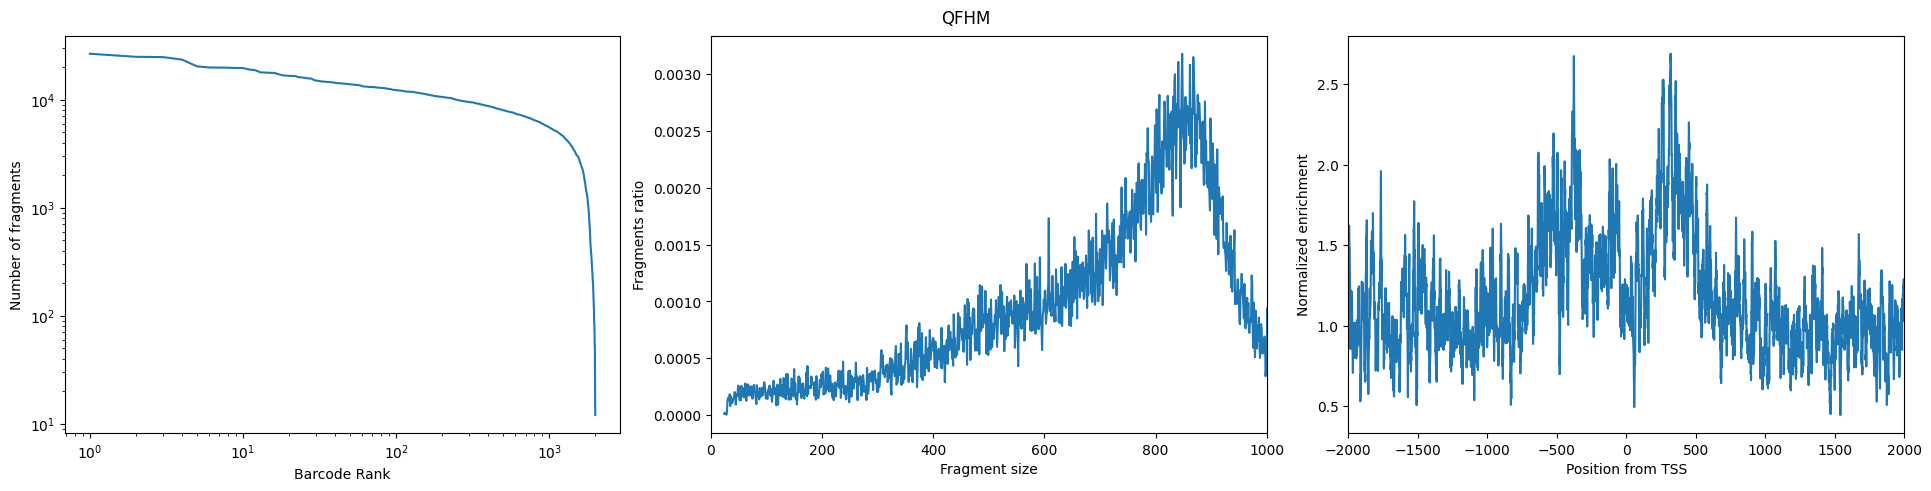

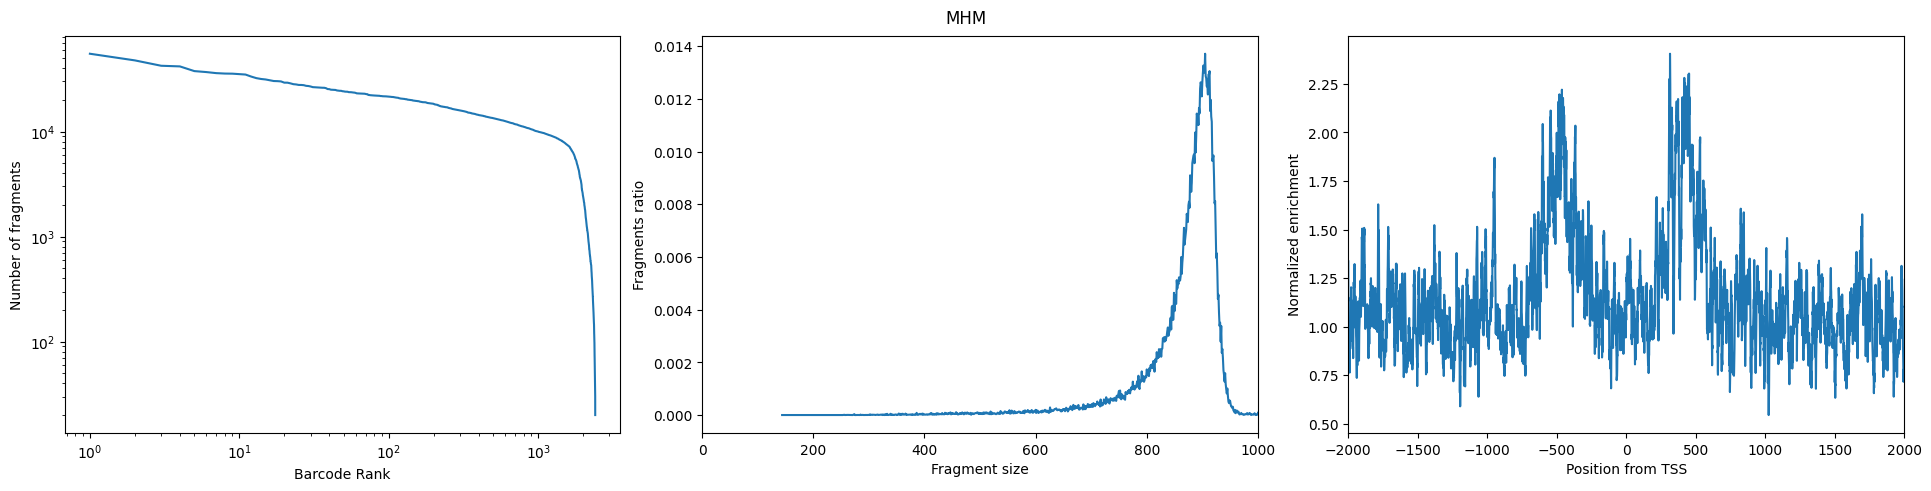

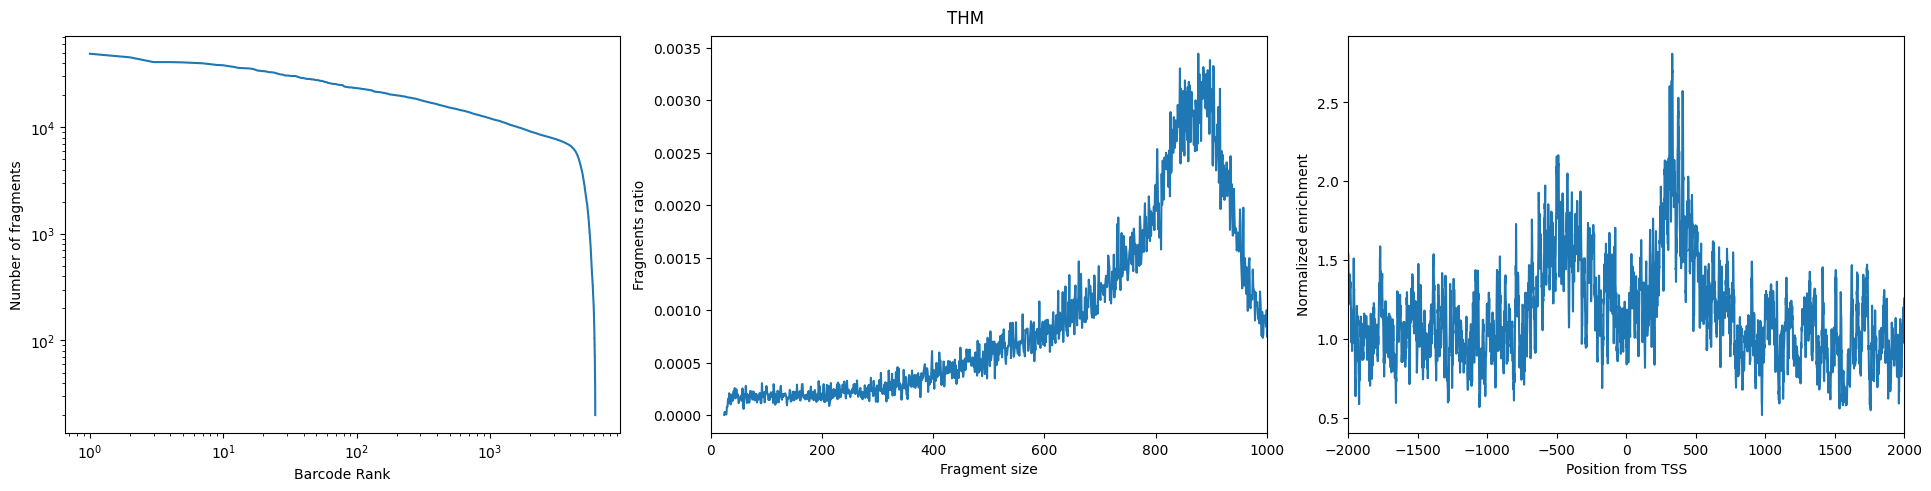

In [14]:
from pycisTopic.plotting.qc_plot import plot_sample_stats, plot_barcode_stats
import matplotlib.pyplot as plt

for sample_id in fragments_dict:
    fig = plot_sample_stats(
        sample_id = sample_id,
        pycistopic_qc_output_dir = "scenic_hm_outs/qc"
    )
## 看中间的图的话，这个peak calling的结果是有问题的...

CYHM:
	Using user-defined threshold for unique fragments: 500
	Using user-defined threshold for TSS enrichment: 0.5
JTHM:
	Using user-defined threshold for unique fragments: 500
	Using user-defined threshold for TSS enrichment: 0.5
QFHM:
	Using user-defined threshold for unique fragments: 500
	Using user-defined threshold for TSS enrichment: 0.5
MHM:
	Using user-defined threshold for unique fragments: 500
	Using user-defined threshold for TSS enrichment: 0.5
THM:
	Using user-defined threshold for unique fragments: 500
	Using user-defined threshold for TSS enrichment: 0.5


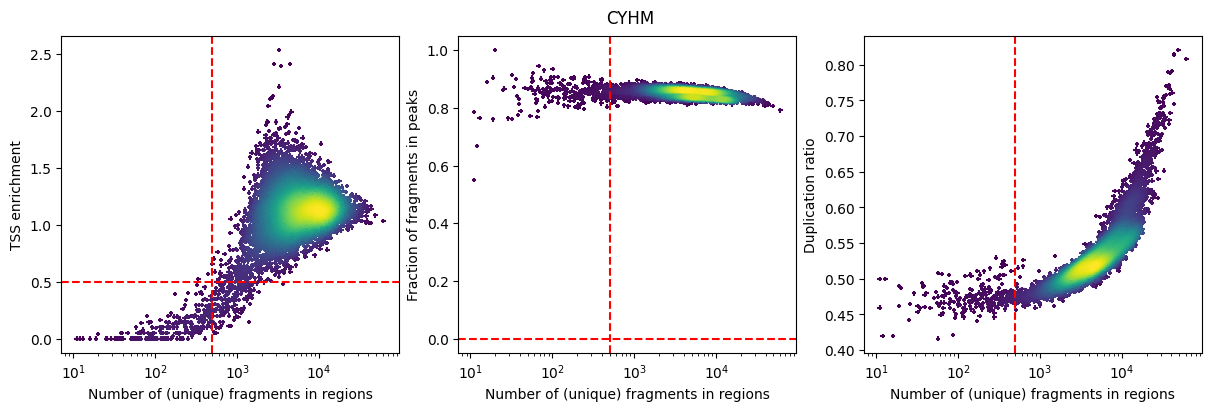

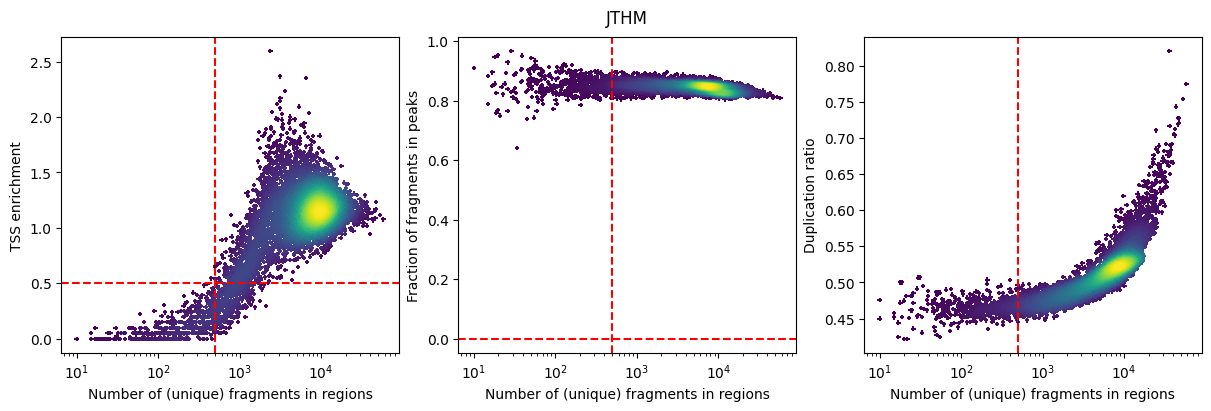

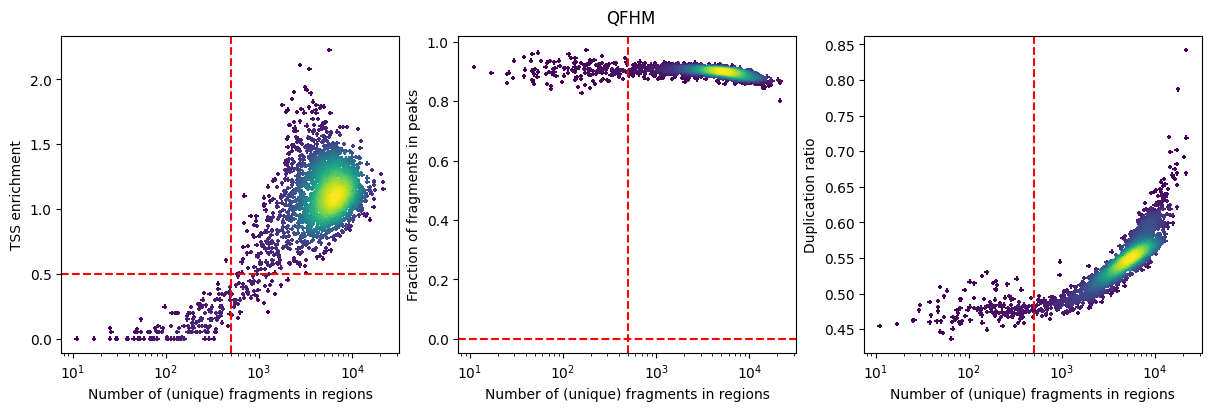

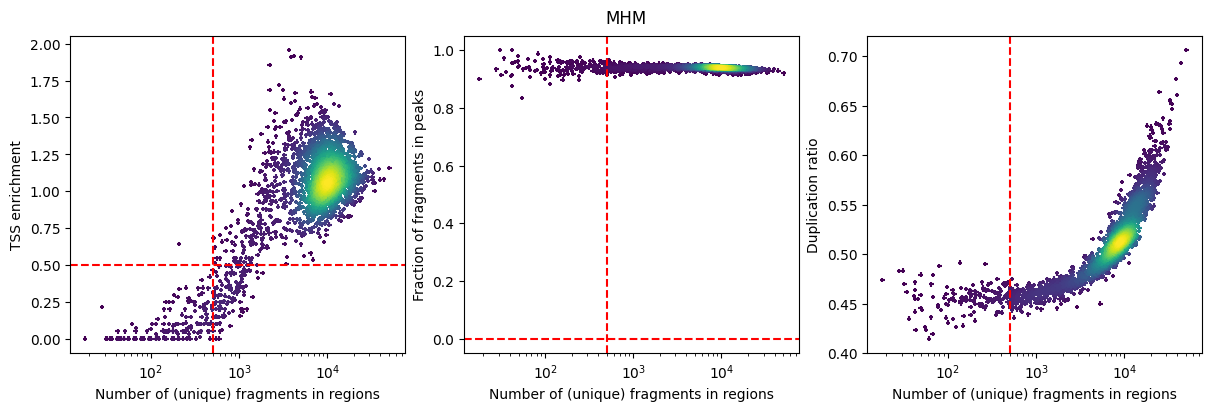

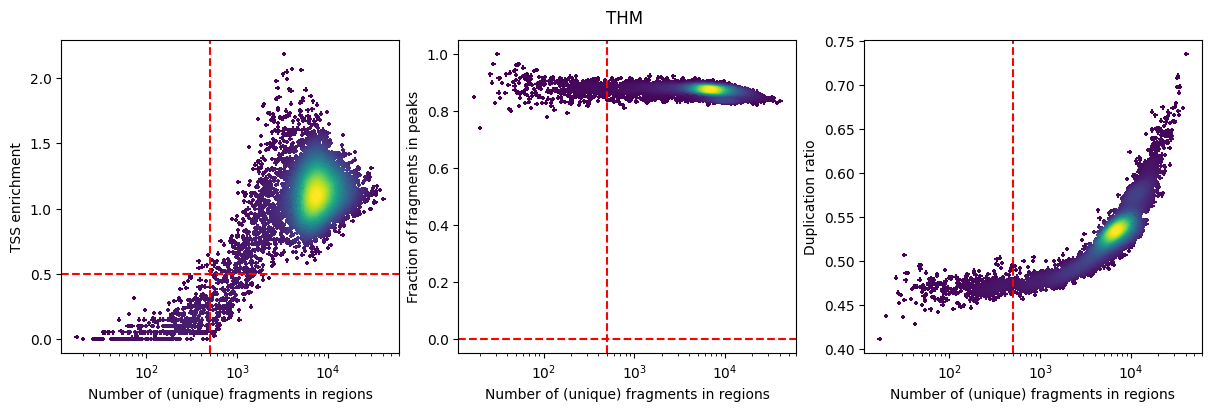

In [15]:
from pycisTopic.qc import get_barcodes_passing_qc_for_sample
sample_id_to_barcodes_passing_filters = {}
sample_id_to_thresholds = {}

for sample_id in fragments_dict:
    (
        sample_id_to_barcodes_passing_filters[sample_id],
        sample_id_to_thresholds[sample_id]
    ) = get_barcodes_passing_qc_for_sample(
            sample_id = sample_id,
            pycistopic_qc_output_dir = os.path.join(out_dir,'qc'),
            unique_fragments_threshold = 500, # use automatic thresholding
            tss_enrichment_threshold = 0.5, # use automatic thresholding
            frip_threshold = 0,
            use_automatic_thresholds = True,
    )

for sample_id in fragments_dict:
    fig = plot_barcode_stats(
        sample_id = sample_id,
        pycistopic_qc_output_dir = os.path.join(out_dir,'qc'),
        bc_passing_filters = sample_id_to_barcodes_passing_filters[sample_id],
        detailed_title = False,
        **sample_id_to_thresholds[sample_id]
    )

## TSS 分数很低

## create cistopic object

In [16]:
path_to_regions = os.path.join(out_dir, "consensus_peak_calling/consensus_regions.bed")
#path_to_blacklist = "pycisTopic/blacklist/hg38-blacklist.v2.bed"
path_to_blacklist="/home/rsun@ZHANGroup.local/projects_list/pycisTopic-main/blacklist/mm10-blacklist.v2.bed"
pycistopic_qc_output_dir = os.path.join(out_dir,'qc')

from pycisTopic.cistopic_class import create_cistopic_object_from_fragments
import polars as pl

cistopic_obj_list = []
for sample_id in fragments_dict:
    sample_metrics = pl.read_parquet(
        os.path.join(pycistopic_qc_output_dir, f'{sample_id}.fragments_stats_per_cb.parquet')
    ).to_pandas().set_index("CB").loc[ sample_id_to_barcodes_passing_filters[sample_id] ]
    cistopic_obj = create_cistopic_object_from_fragments(
        path_to_fragments = fragments_dict[sample_id],
        path_to_regions = path_to_regions,
        path_to_blacklist = path_to_blacklist,
        metrics = sample_metrics,
        valid_bc = sample_id_to_barcodes_passing_filters[sample_id],
        n_cpu = 1,
        project = sample_id,
        split_pattern = '-'
    )
    cistopic_obj_list.append(cistopic_obj)

2025-06-19 06:24:43,486 cisTopic     INFO     Reading data for CYHM


2025-06-19 06:25:05,005 cisTopic     INFO     metrics provided!
2025-06-19 06:25:06,519 cisTopic     INFO     Counting fragments in regions
2025-06-19 06:25:19,162 cisTopic     INFO     Creating fragment matrix
2025-06-19 06:25:43,325 cisTopic     INFO     Converting fragment matrix to sparse matrix
2025-06-19 06:25:46,187 cisTopic     INFO     Removing blacklisted regions
2025-06-19 06:25:46,470 cisTopic     INFO     Creating CistopicObject
2025-06-19 06:25:47,413 cisTopic     INFO     Done!
2025-06-19 06:25:47,494 cisTopic     INFO     Reading data for JTHM
2025-06-19 06:26:10,507 cisTopic     INFO     metrics provided!
2025-06-19 06:26:12,049 cisTopic     INFO     Counting fragments in regions
2025-06-19 06:26:26,232 cisTopic     INFO     Creating fragment matrix
2025-06-19 06:26:52,468 cisTopic     INFO     Converting fragment matrix to sparse matrix
2025-06-19 06:26:55,890 cisTopic     INFO     Removing blacklisted regions
2025-06-19 06:26:56,246 cisTopic     INFO     Creating Cis

In [18]:
for ele in cistopic_obj_list:
    ## 只有很少的细胞能通过QC
    print(ele)

''' 自动化QC的结果
CistopicObject from project CYHM with n_cells × n_regions = 628 × 100050
CistopicObject from project JTHM with n_cells × n_regions = 865 × 119459
CistopicObject from project QFHM with n_cells × n_regions = 399 × 65901
CistopicObject from project MHM with n_cells × n_regions = 431 × 128405
CistopicObject from project THM with n_cells × n_regions = 1161 × 109110
'''

CistopicObject from project CYHM with n_cells × n_regions = 4941 × 100069
CistopicObject from project JTHM with n_cells × n_regions = 4946 × 119466
CistopicObject from project QFHM with n_cells × n_regions = 1799 × 66177
CistopicObject from project MHM with n_cells × n_regions = 2140 × 128464
CistopicObject from project THM with n_cells × n_regions = 5583 × 109115


' 自动化QC的结果\nCistopicObject from project CYHM with n_cells × n_regions = 628 × 100050\nCistopicObject from project JTHM with n_cells × n_regions = 865 × 119459\nCistopicObject from project QFHM with n_cells × n_regions = 399 × 65901\nCistopicObject from project MHM with n_cells × n_regions = 431 × 128405\nCistopicObject from project THM with n_cells × n_regions = 1161 × 109110\n'

In [19]:
from pycisTopic.cistopic_class import merge 
import pickle 
cistopic_obj = merge(cistopic_obj_list, split_pattern = '-')
print(cistopic_obj)
cistopic_obj.add_cell_data(cell_data, split_pattern='-')
pickle.dump(
    cistopic_obj,
    open(os.path.join(out_dir, "cistopic_obj.pkl"), "wb")
)
pd.crosstab(cistopic_obj.cell_data.loc[:,'species'], cistopic_obj.cell_data.loc[:,'leiden'])

2025-06-19 06:31:16,004 cisTopic     INFO     cisTopic object 1 merged
2025-06-19 06:31:20,480 cisTopic     INFO     cisTopic object 2 merged
2025-06-19 06:31:30,066 cisTopic     INFO     cisTopic object 3 merged
2025-06-19 06:31:42,976 cisTopic     INFO     cisTopic object 4 merged
CistopicObject from project cisTopic_merge with n_cells × n_regions = 19409 × 252091


leiden,0,1,2,3,4,5,6,7,8,9,10
species,,,,,,,,,,,
CY,1262,779,1085,0,736,0,552,203,276,48,0
JT,1086,875,1030,21,768,0,458,249,424,35,0
M,0,191,33,507,21,760,0,135,121,246,126
QF,0,500,33,508,0,354,0,219,41,19,125
T,3501,186,134,710,46,0,22,345,158,238,243


In [41]:
cistopic_obj.cell_data.head()

,cisTopic_nr_frag,cisTopic_log_nr_frag,cisTopic_nr_acc,cisTopic_log_nr_acc,sample_id,barcode_rank,total_fragments_count,log10_total_fragments_count,unique_fragments_count,log10_unique_fragments_count,...,nucleosome_signal,tss_enrichment,pdf_values_for_tss_enrichment,pdf_values_for_fraction_of_fragments_in_peaks,pdf_values_for_duplication_ratio,barcode,leiden,eco,species,sample
CAAGTATGTCCTAACT-1-CYHM,7064,3.849051,7056,3.848559,CYHM,1981,18093,4.257535,8062,3.906497,...,1.239011,0.921896,1.008845,25.422807,13.512598,CAAGTATGTCCTAACT-1,0,eco,CY,CYHM
CTTGAATCATCCCTCA-1-CYHM,7273,3.861714,7264,3.861176,CYHM,1910,18702,4.271911,8325,3.920436,...,1.179028,1.141015,1.945027,25.449857,13.790426,CTTGAATCATCCCTCA-1,1,eco,CY,CYHM
CTTGCTCAGAAAGCAT-1-CYHM,12290,4.089552,12269,4.088809,CYHM,816,32842,4.516443,14472,4.160559,...,1.196949,1.422970,0.434937,21.792894,14.253199,CTTGCTCAGAAAGCAT-1,2,eco,CY,CYHM
CTTGTAAAGAATCTCA-1-CYHM,11343,4.054728,11322,4.053923,CYHM,958,29433,4.468849,13322,4.124602,...,1.177469,1.111859,2.017601,21.924476,14.927688,CTTGTAAAGAATCTCA-1,2,eco,CY,CYHM
CTTTAGTTCATGGTTA-1-CYHM,15259,4.183526,15233,4.182785,CYHM,388,41808,4.621270,17965,4.254451,...,1.120442,1.122004,1.671512,18.263576,9.398201,CTTTAGTTCATGGTTA-1,4,eco,CY,CYHM


## run models

In [20]:
lda_path = os.path.join(out_dir, 'lda_models')
os.makedirs(lda_path, exist_ok=True)
os.environ['MALLET_MEMORY'] = '200G'
from pycisTopic.lda_models import run_cgs_models_mallet
# Configure path Mallet
mallet_path="/home/rsun@ZHANGroup.local/projects_list/Mallet-202108/bin/mallet"
# Run models
models=run_cgs_models_mallet(
    cistopic_obj,
    n_topics=[ 5, 15,  25, 35, 45, 50],
    n_cpu=128,
    n_iter=500,
    random_state=555,
    alpha=50,
    alpha_by_topic=True,
    eta=0.1,
    eta_by_topic=False,
    tmp_path=lda_path,
    save_path=lda_path,
    mallet_path=mallet_path,
)

2025-06-19 06:34:43,580 cisTopic     INFO     Formatting input to corpus
2025-06-19 06:34:44,897 cisTopic     INFO     Running model with 5 topics
2025-06-19 06:34:44,898 LDAMalletWrapper INFO     Serializing temporary corpus to scenic_hm_outs/lda_models/corpus.txt
2025-06-19 06:35:31,355 LDAMalletWrapper INFO     Converting temporary corpus to MALLET format with: /home/rsun@ZHANGroup.local/projects_list/Mallet-202108/bin/mallet import-file --preserve-case --keep-sequence --token-regex \S+ --input scenic_hm_outs/lda_models/corpus.txt --output scenic_hm_outs/lda_models/corpus.mallet
2025-06-19 06:36:14,510 LDAMalletWrapper INFO     Training MALLET LDA with: /home/rsun@ZHANGroup.local/projects_list/Mallet-202108/bin/mallet train-topics --input scenic_hm_outs/lda_models/corpus.mallet --num-topics 5 --alpha 50 --beta 0.1 --optimize-interval 0 --num-threads 128 --output-state scenic_hm_outs/lda_models/10f6ff_state.mallet.gz --output-doc-topics scenic_hm_outs/lda_models/10f6ff_doctopics.txt 

In [21]:
pickle.dump(
    models,
    open(os.path.join(lda_path, "models.pkl"), "wb")
)

## model selection

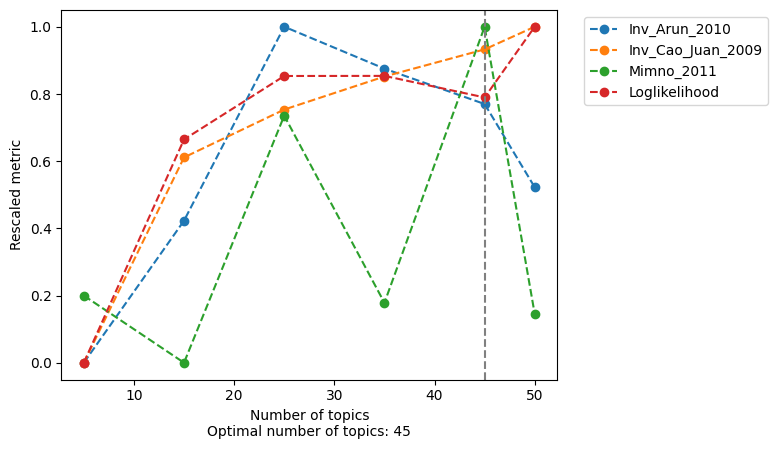

In [23]:
from pycisTopic.lda_models import evaluate_models
model = evaluate_models(
    models,
    select_model = 45,
    return_model = True
)

In [ ]:
cistopic_obj.add_LDA_model(model)
pickle.dump(
    cistopic_obj,
    open(os.path.join(out_dir, "cistopic_obj.pkl"), "wb")
)



## 加载先前的模型和cistopic object进行分析

/home/rsun@ZHANGroup.local/anaconda3/envs/scenicplus/lib/python3.11/site-packages/pycisTopic/__init__.py:3: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import DistributionNotFound, get_distribution
/home/rsun@ZHANGroup.local/anaconda3/envs/scenicplus/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
2025-06-26 04:38:55,330	INFO util.py:154 -- Missing packages: ['ipywidgets']. Run `pip install -U ipywidgets`, then restart the notebook server for rich notebook output.


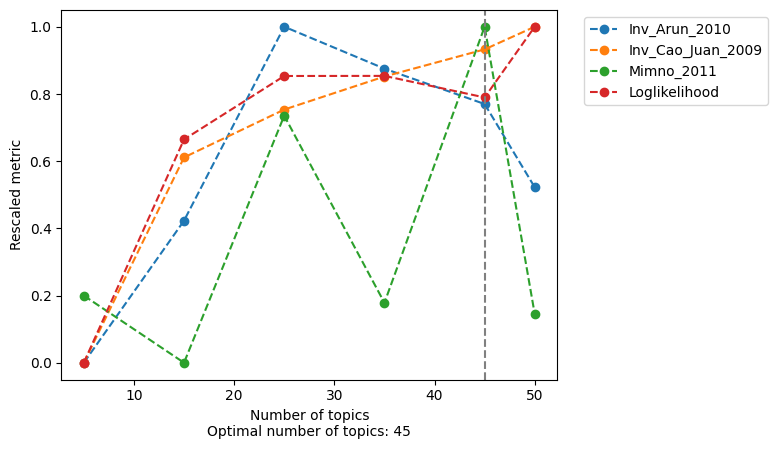

In [1]:
import pickle
import pandas as pd 
import numpy as np 
import scanpy as sc
import pycisTopic
pycisTopic.__version__

import os
out_dir = "scenic_hm_outs"
os.makedirs(out_dir, exist_ok = True)

file_path = os.path.join(out_dir, "cistopic_obj.pkl")

with open(file_path, 'rb') as file:
    cistopic_obj = pickle.load(file)

lda_path = os.path.join(out_dir, 'lda_models')
file_path = os.path.join(lda_path, "models.pkl")
with open(file_path, 'rb') as file:
    models = pickle.load(file)

from pycisTopic.lda_models import evaluate_models
model = evaluate_models(
    models,
    select_model = 45,
    return_model = True
)


## cluster and vis

2025-06-19 10:13:46,803 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...


2025-06-19 10:13:46,803 harmonypy    INFO     Computing initial centroids with sklearn.KMeans...


2025-06-19 10:13:48,063 - harmonypy - INFO - sklearn.KMeans initialization complete.


2025-06-19 10:13:48,063 harmonypy    INFO     sklearn.KMeans initialization complete.


2025-06-19 10:13:48,117 - harmonypy - INFO - Iteration 1 of 40


...

2025-06-19 10:13:50,287 - harmonypy - INFO - Iteration 3 of 40


2025-06-19 10:13:50,287 harmonypy    INFO     Iteration 3 of 40


2025-06-19 10:13:51,240 - harmonypy - INFO - Converged after 3 iterations


2025-06-19 10:13:51,240 harmonypy    INFO     Converged after 3 iterations
2025-06-19 10:13:51,243 cisTopic     INFO     Finding neighbours
Columns ['pycisTopic_leiden_10_1'] will be overwritten
2025-06-19 10:13:53,093 cisTopic     INFO     Running UMAP


/home/rsun@ZHANGroup.local/anaconda3/envs/scenicplus/lib/python3.11/site-packages/umap/umap_.py:1943: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(f"n_jobs value {self.n_jobs} overridden to 1 by setting random_state. Use no seed for parallelism.")


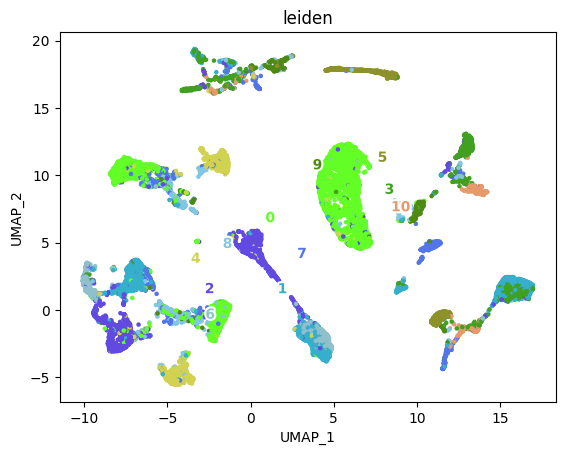

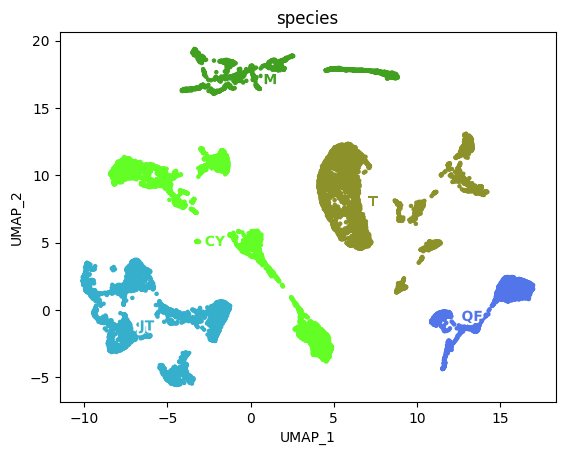

: 

In [ ]:
from pycisTopic.clust_vis import (
    find_clusters,
    run_umap,
    run_tsne,
    plot_metadata,
    plot_topic,
    cell_topic_heatmap
)

pycisTopic.clust_vis.harmony(cistopic_obj, vars_use=['species'],
    max_iter_harmony = 40, sigma =1.0, random_state = 0,theta = 10)

find_clusters(
    cistopic_obj,
    target  = 'cell',
    k = 10,
    res = [1],
    prefix = 'pycisTopic_',
    scale = True,
    split_pattern = '-'
)

run_umap(
    cistopic_obj,
    target  = 'cell', harmony = True, scale=True)

tmp = []
for i,ele in enumerate(cistopic_obj.cell_data.leiden.values):
    tmp.append(str(ele))
cistopic_obj.cell_data.loc[:,'leiden'] = tmp
cistopic_obj.cell_data.leiden

plot_metadata(
    cistopic_obj,
    reduction_name='UMAP',
    variables=['leiden','species'],
    target='cell',
    text_size=10,
    dot_size=5)

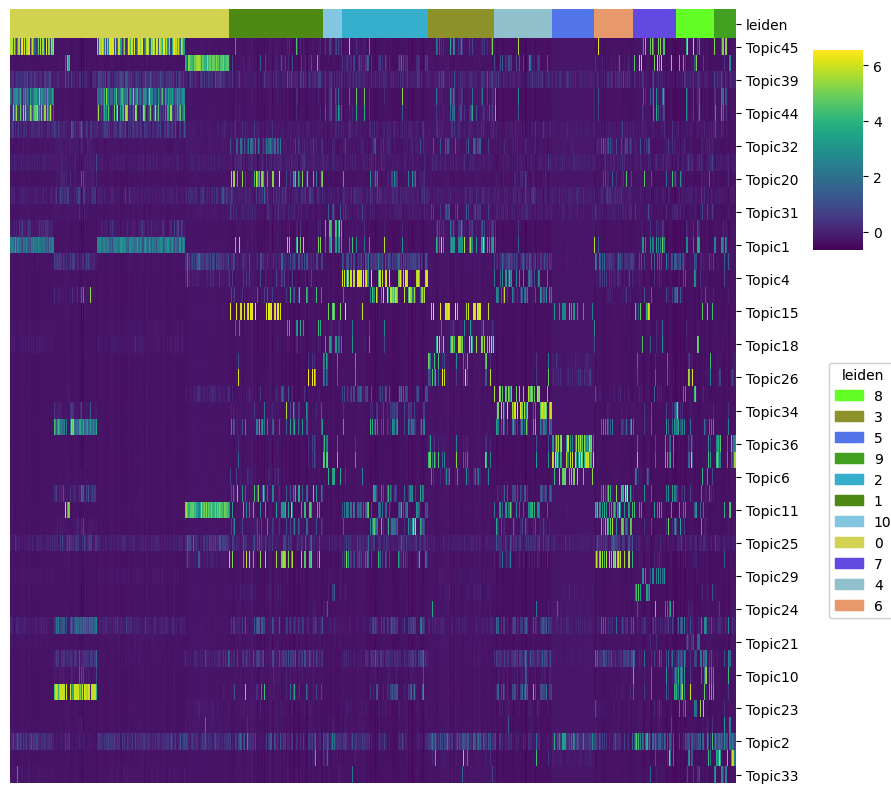

In [3]:
from pycisTopic.clust_vis import (
    find_clusters,
    run_umap,
    run_tsne,
    plot_metadata,
    plot_topic,
    cell_topic_heatmap
)

cell_topic_heatmap(
    cistopic_obj,
    variables = ['leiden'],
    scale = True,
    legend_loc_x = 1.0,
    legend_loc_y = -1.2,
    legend_dist_y = -1,
    figsize = (10, 10)
)

## topic binarization 

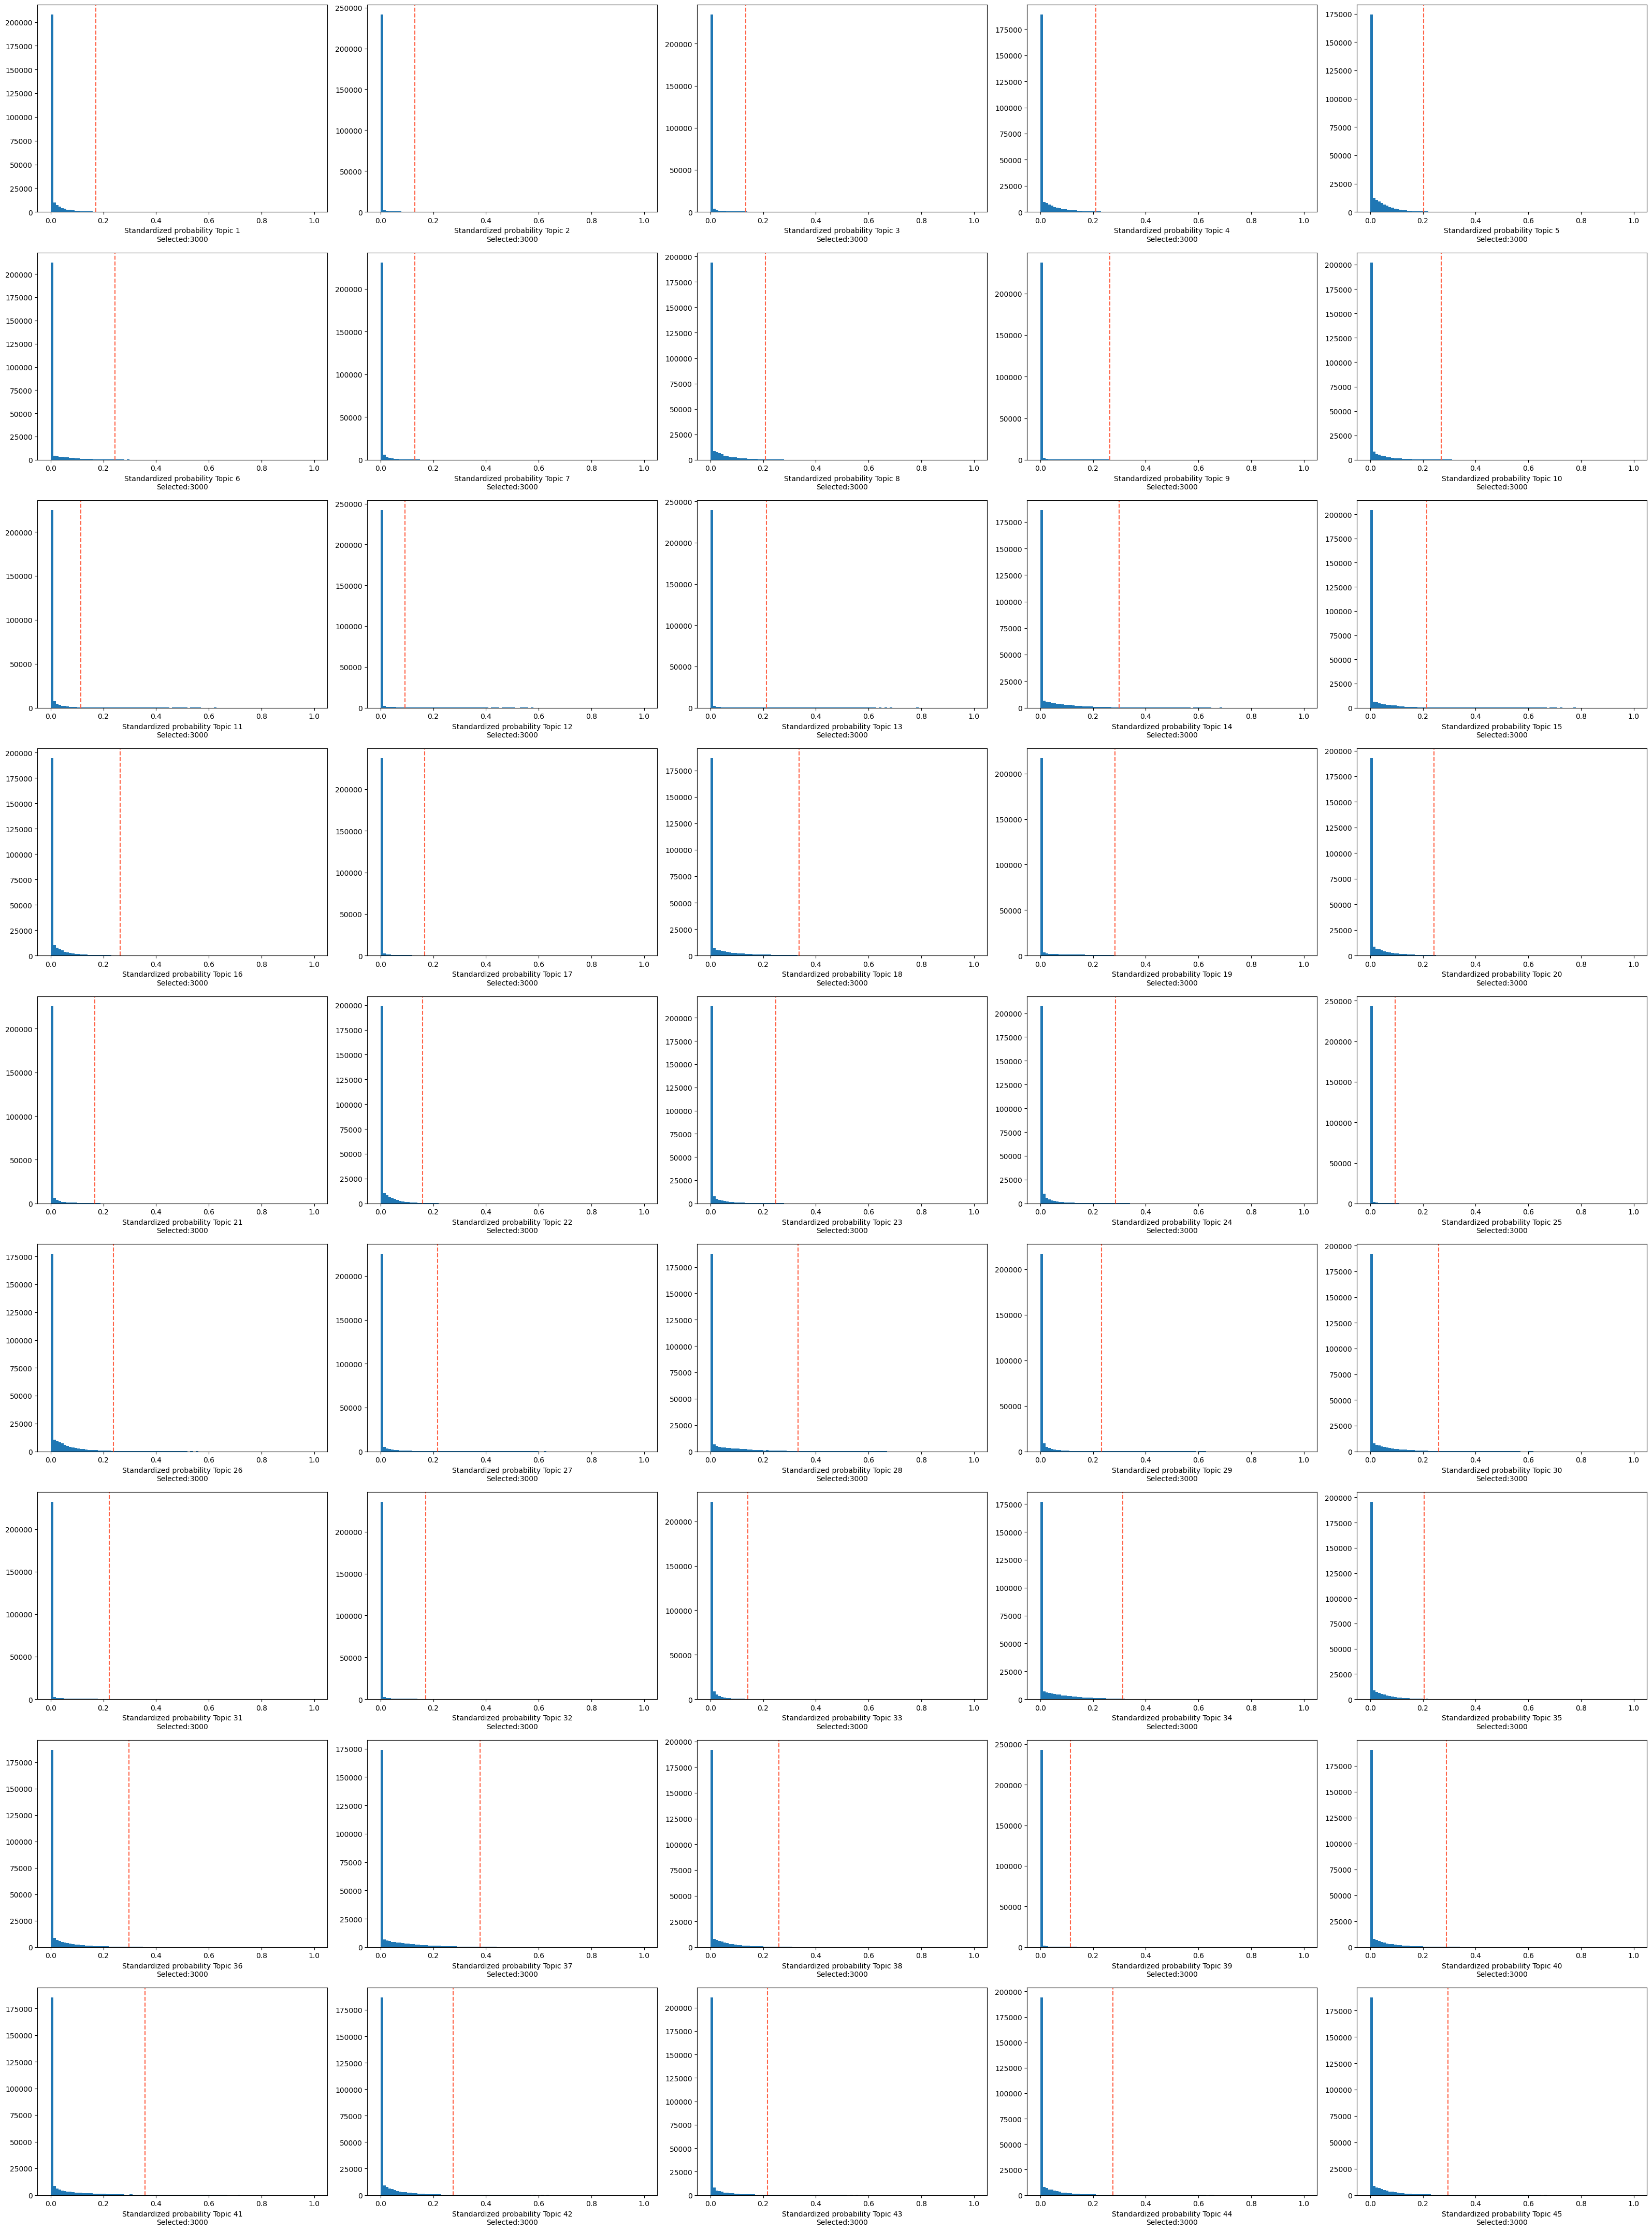

In [23]:
from pycisTopic.topic_binarization import binarize_topics
region_bin_topics_top_3k = binarize_topics(
    cistopic_obj, method='ntop', ntop = 3_000,
    plot=True, num_columns=5
)

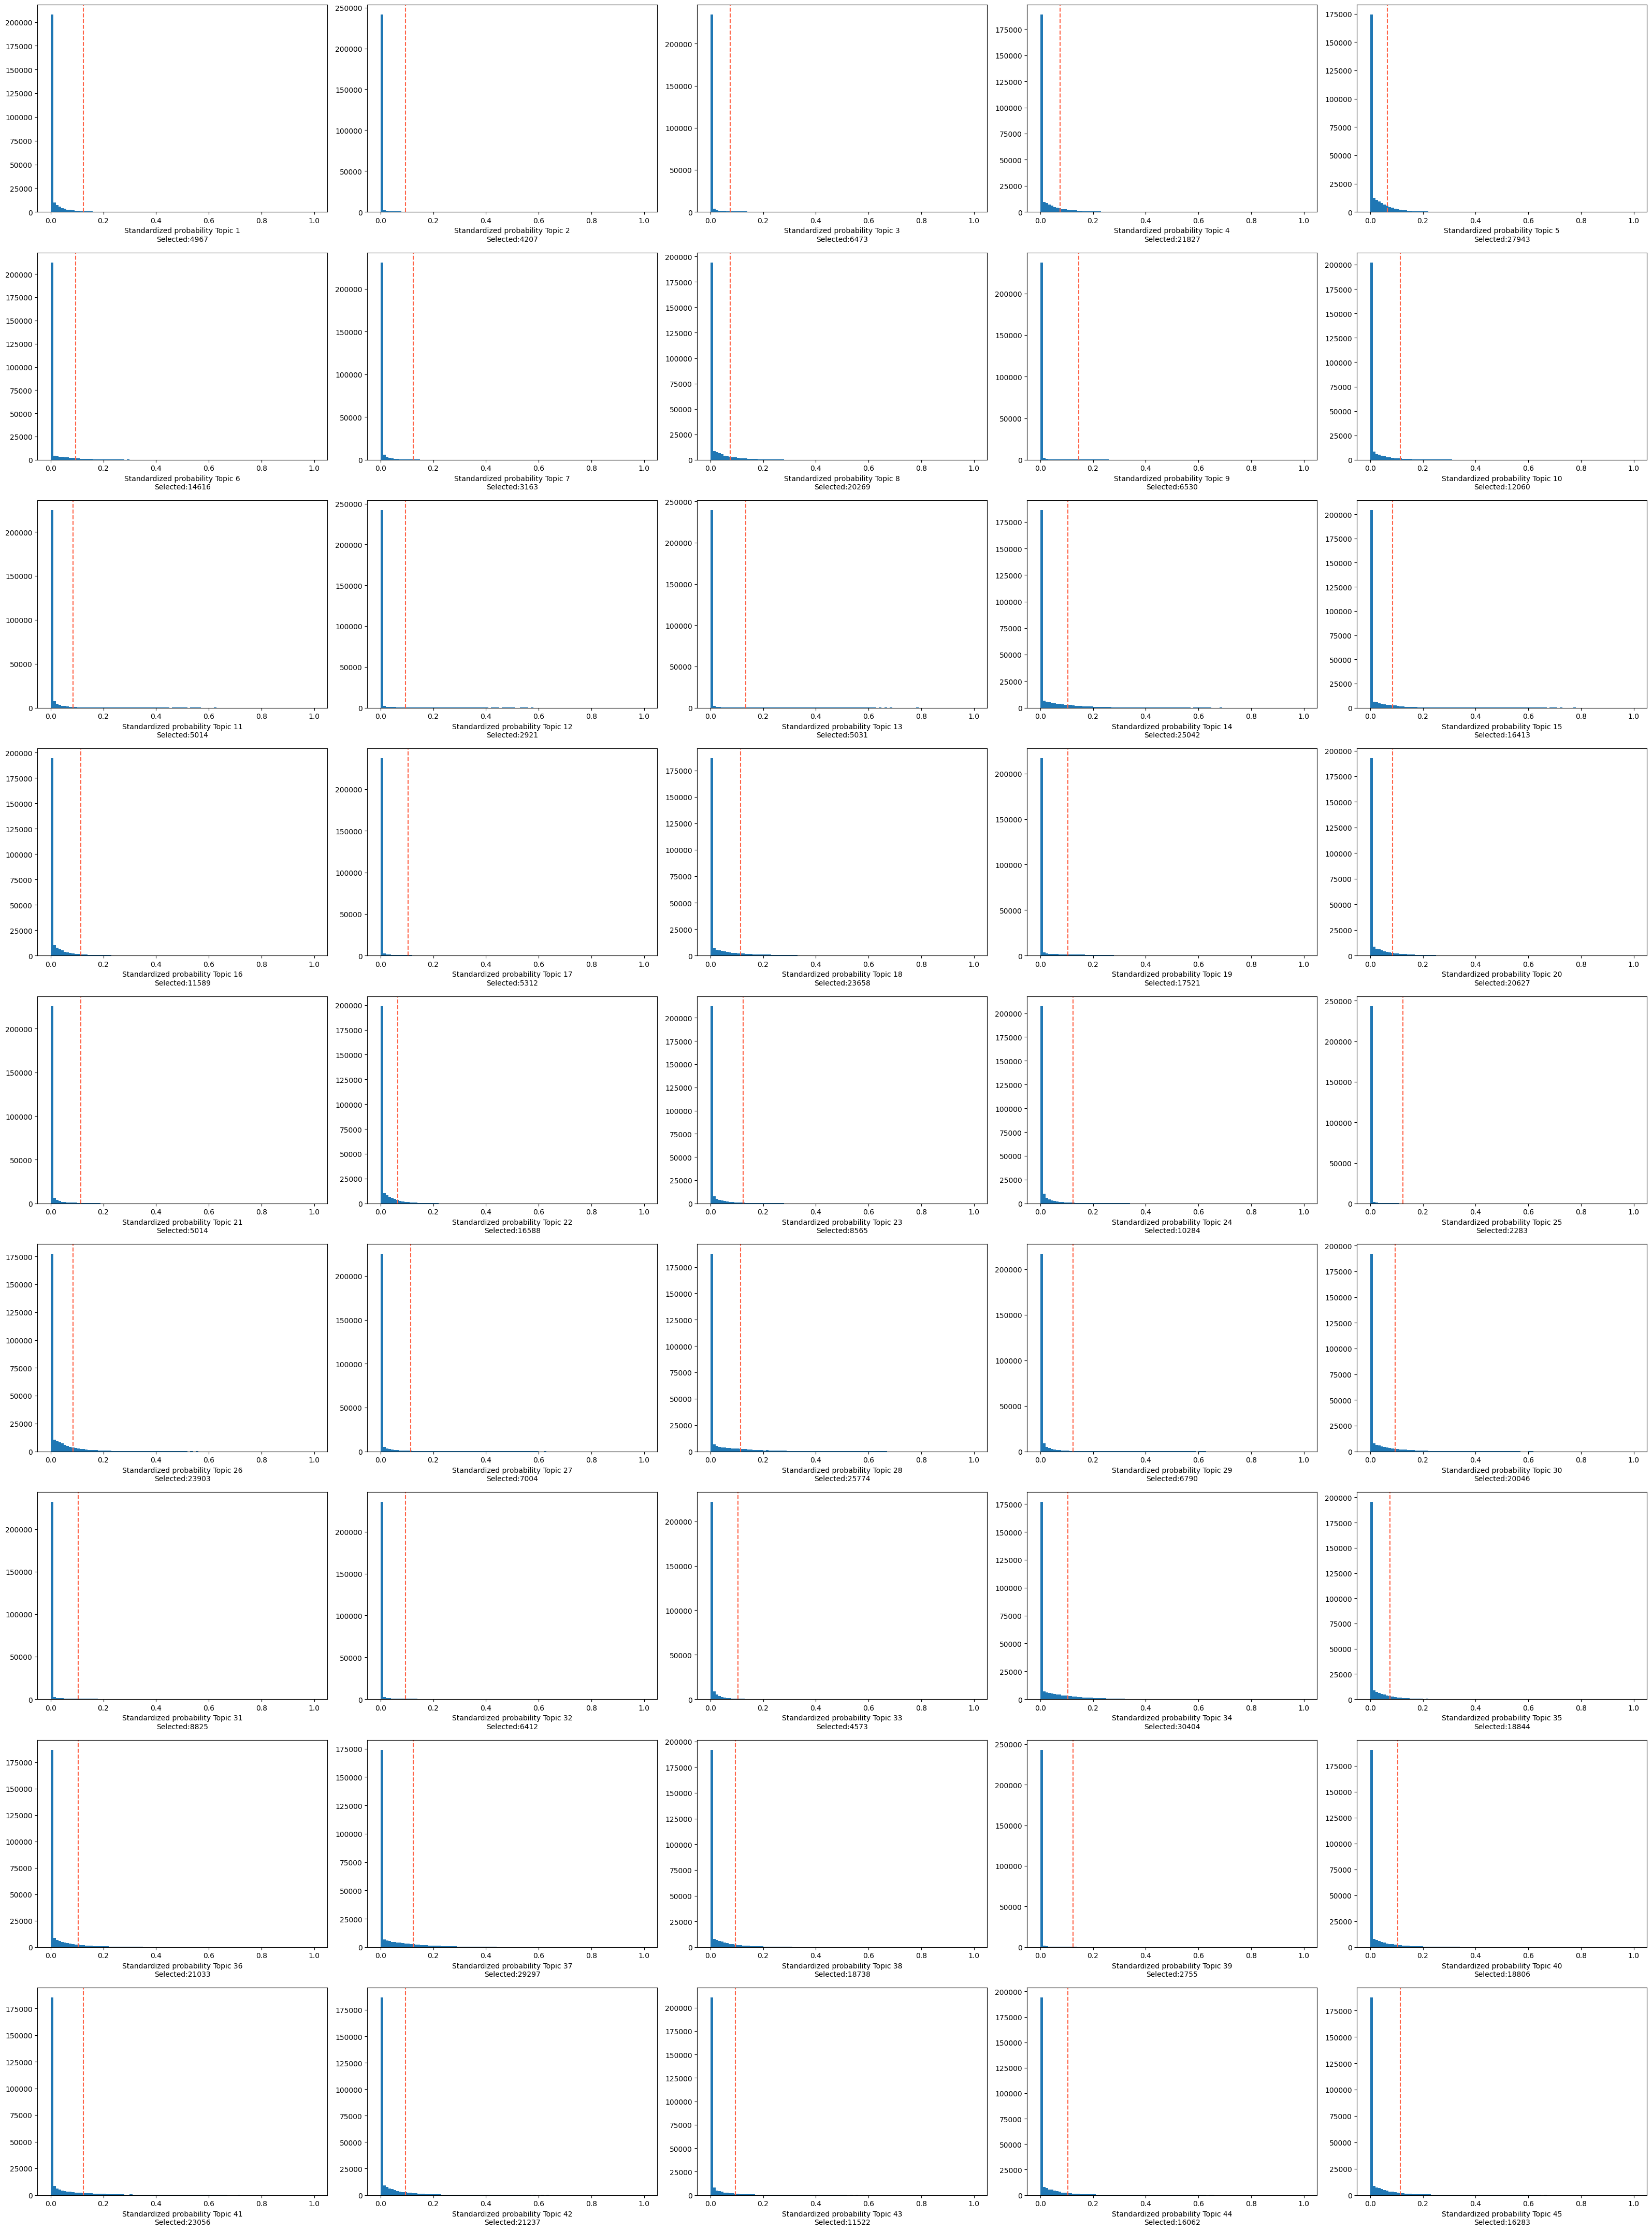

In [24]:
region_bin_topics_otsu = binarize_topics(
    cistopic_obj, method='otsu',
    plot=True, num_columns=5
)

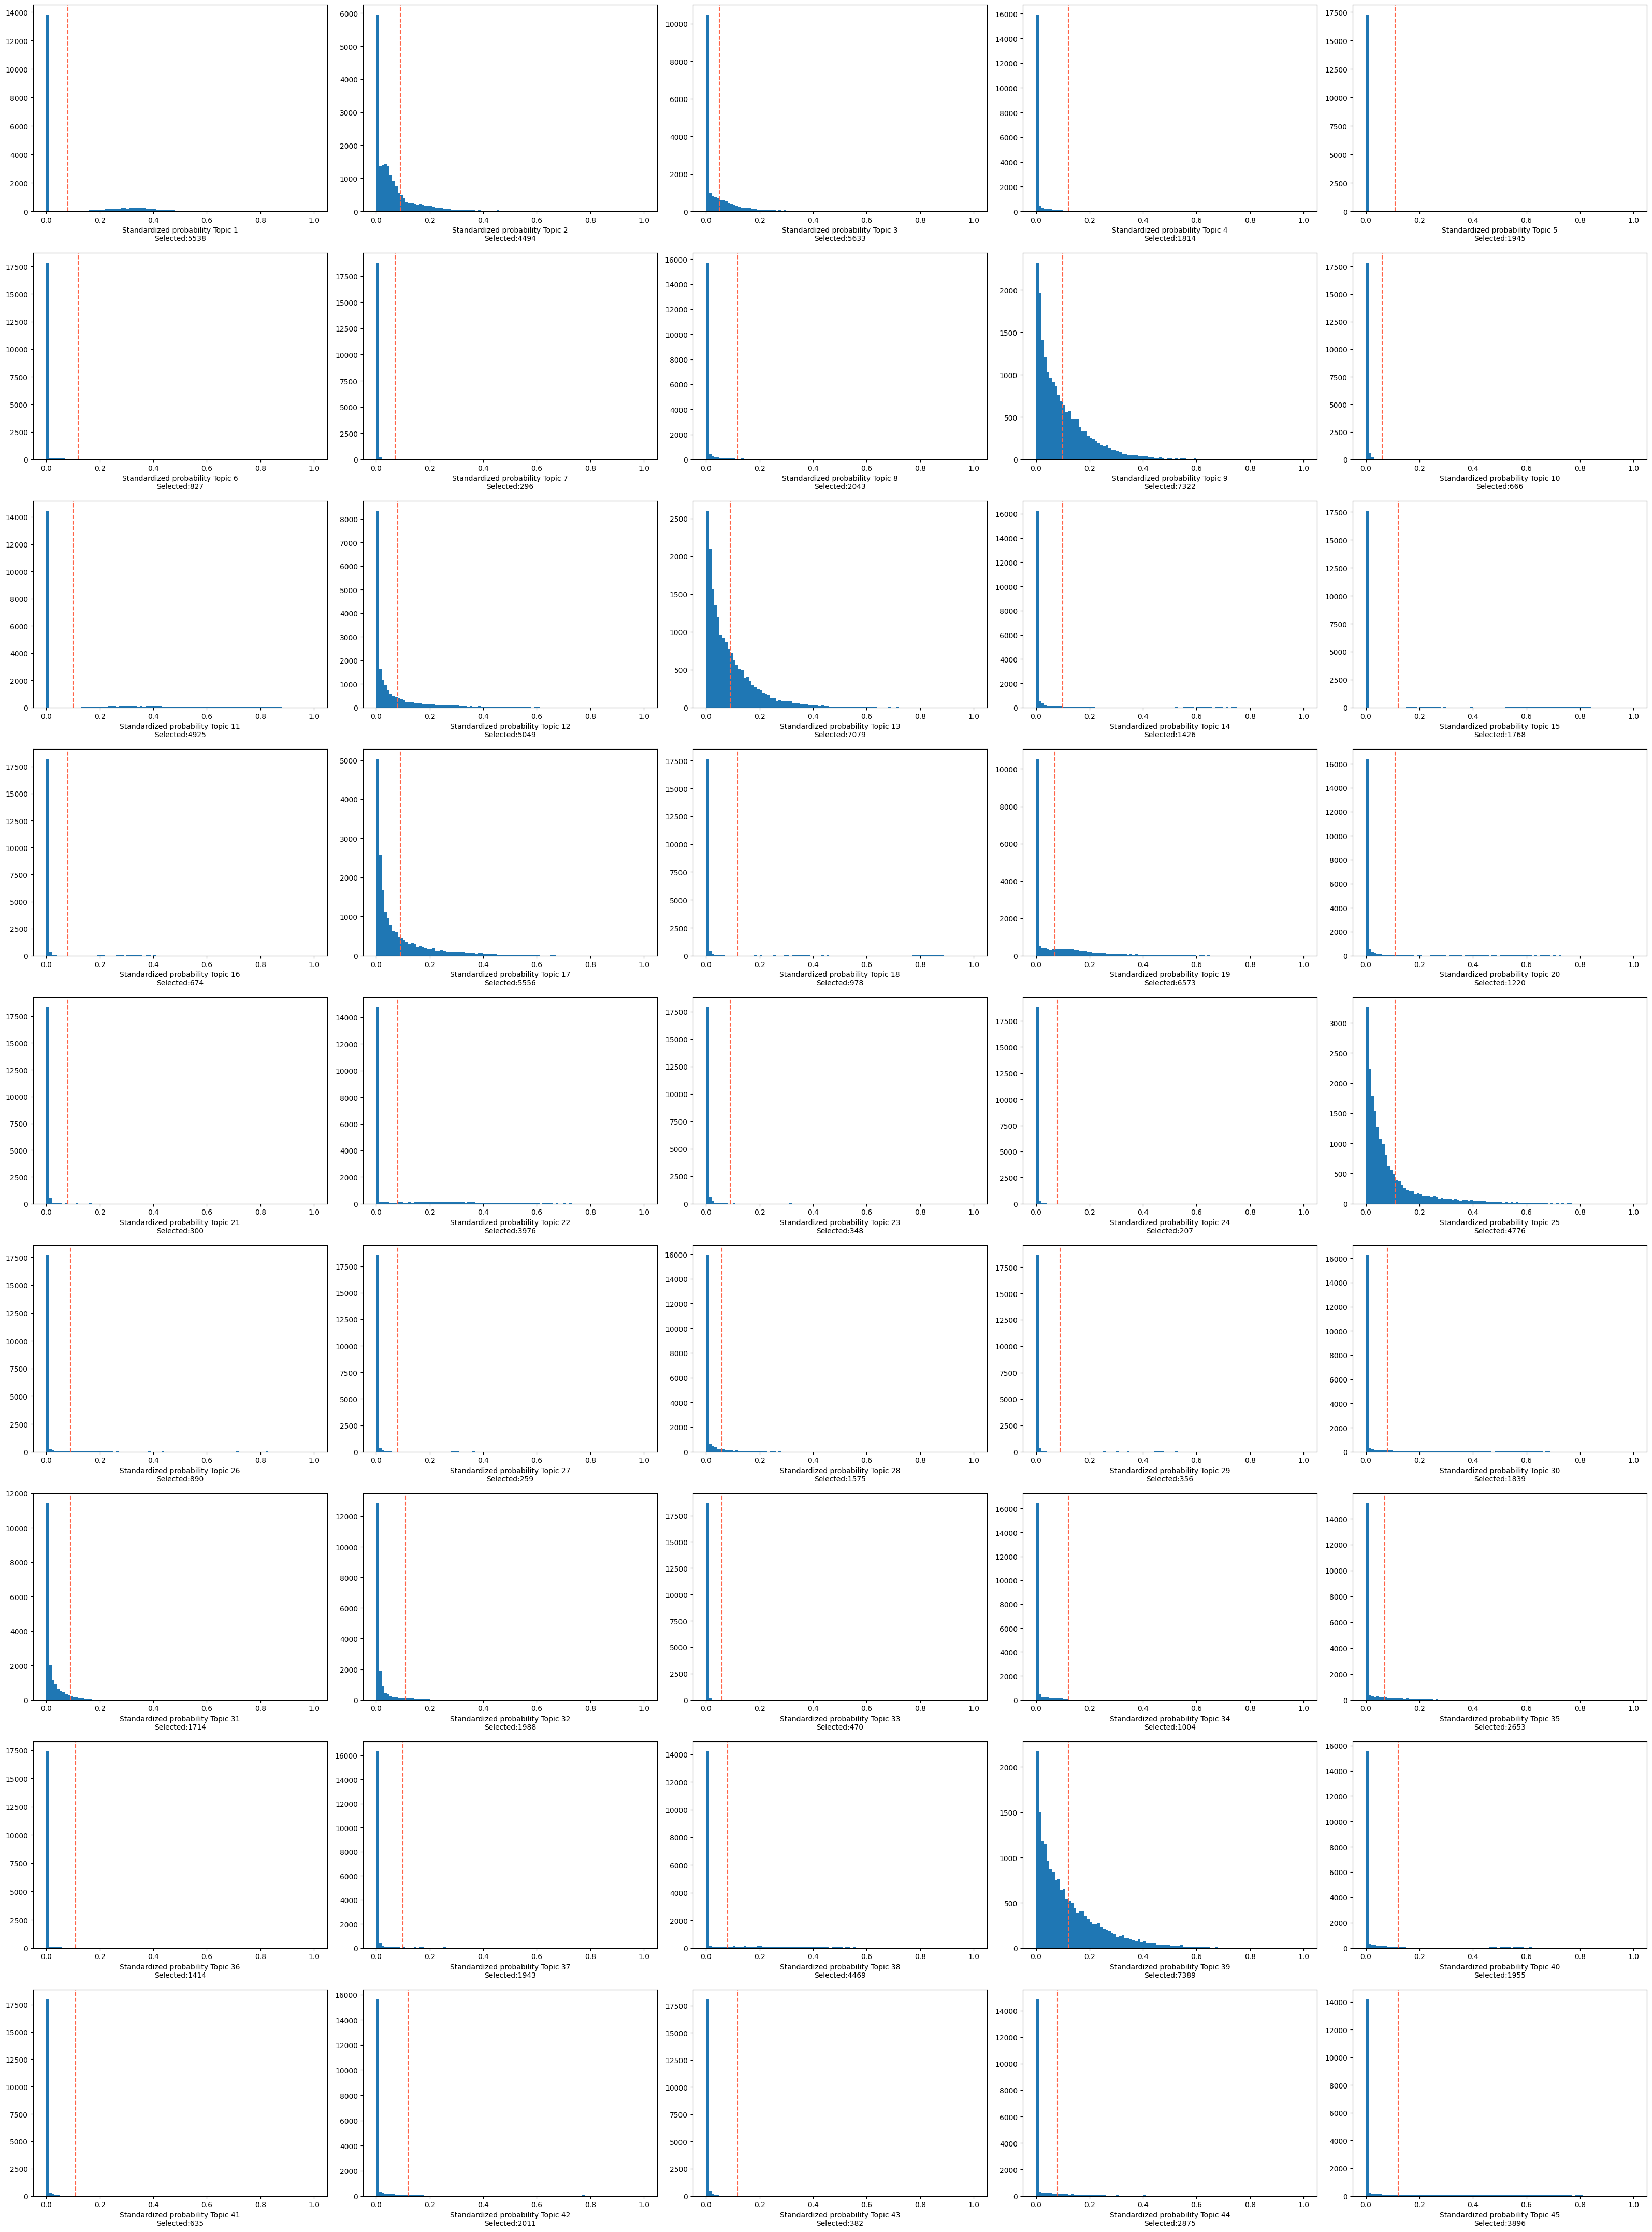

In [25]:
binarized_cell_topic = binarize_topics(
    cistopic_obj,
    target='cell',
    method='li',
    plot=True,
    num_columns=5, nbins=100)

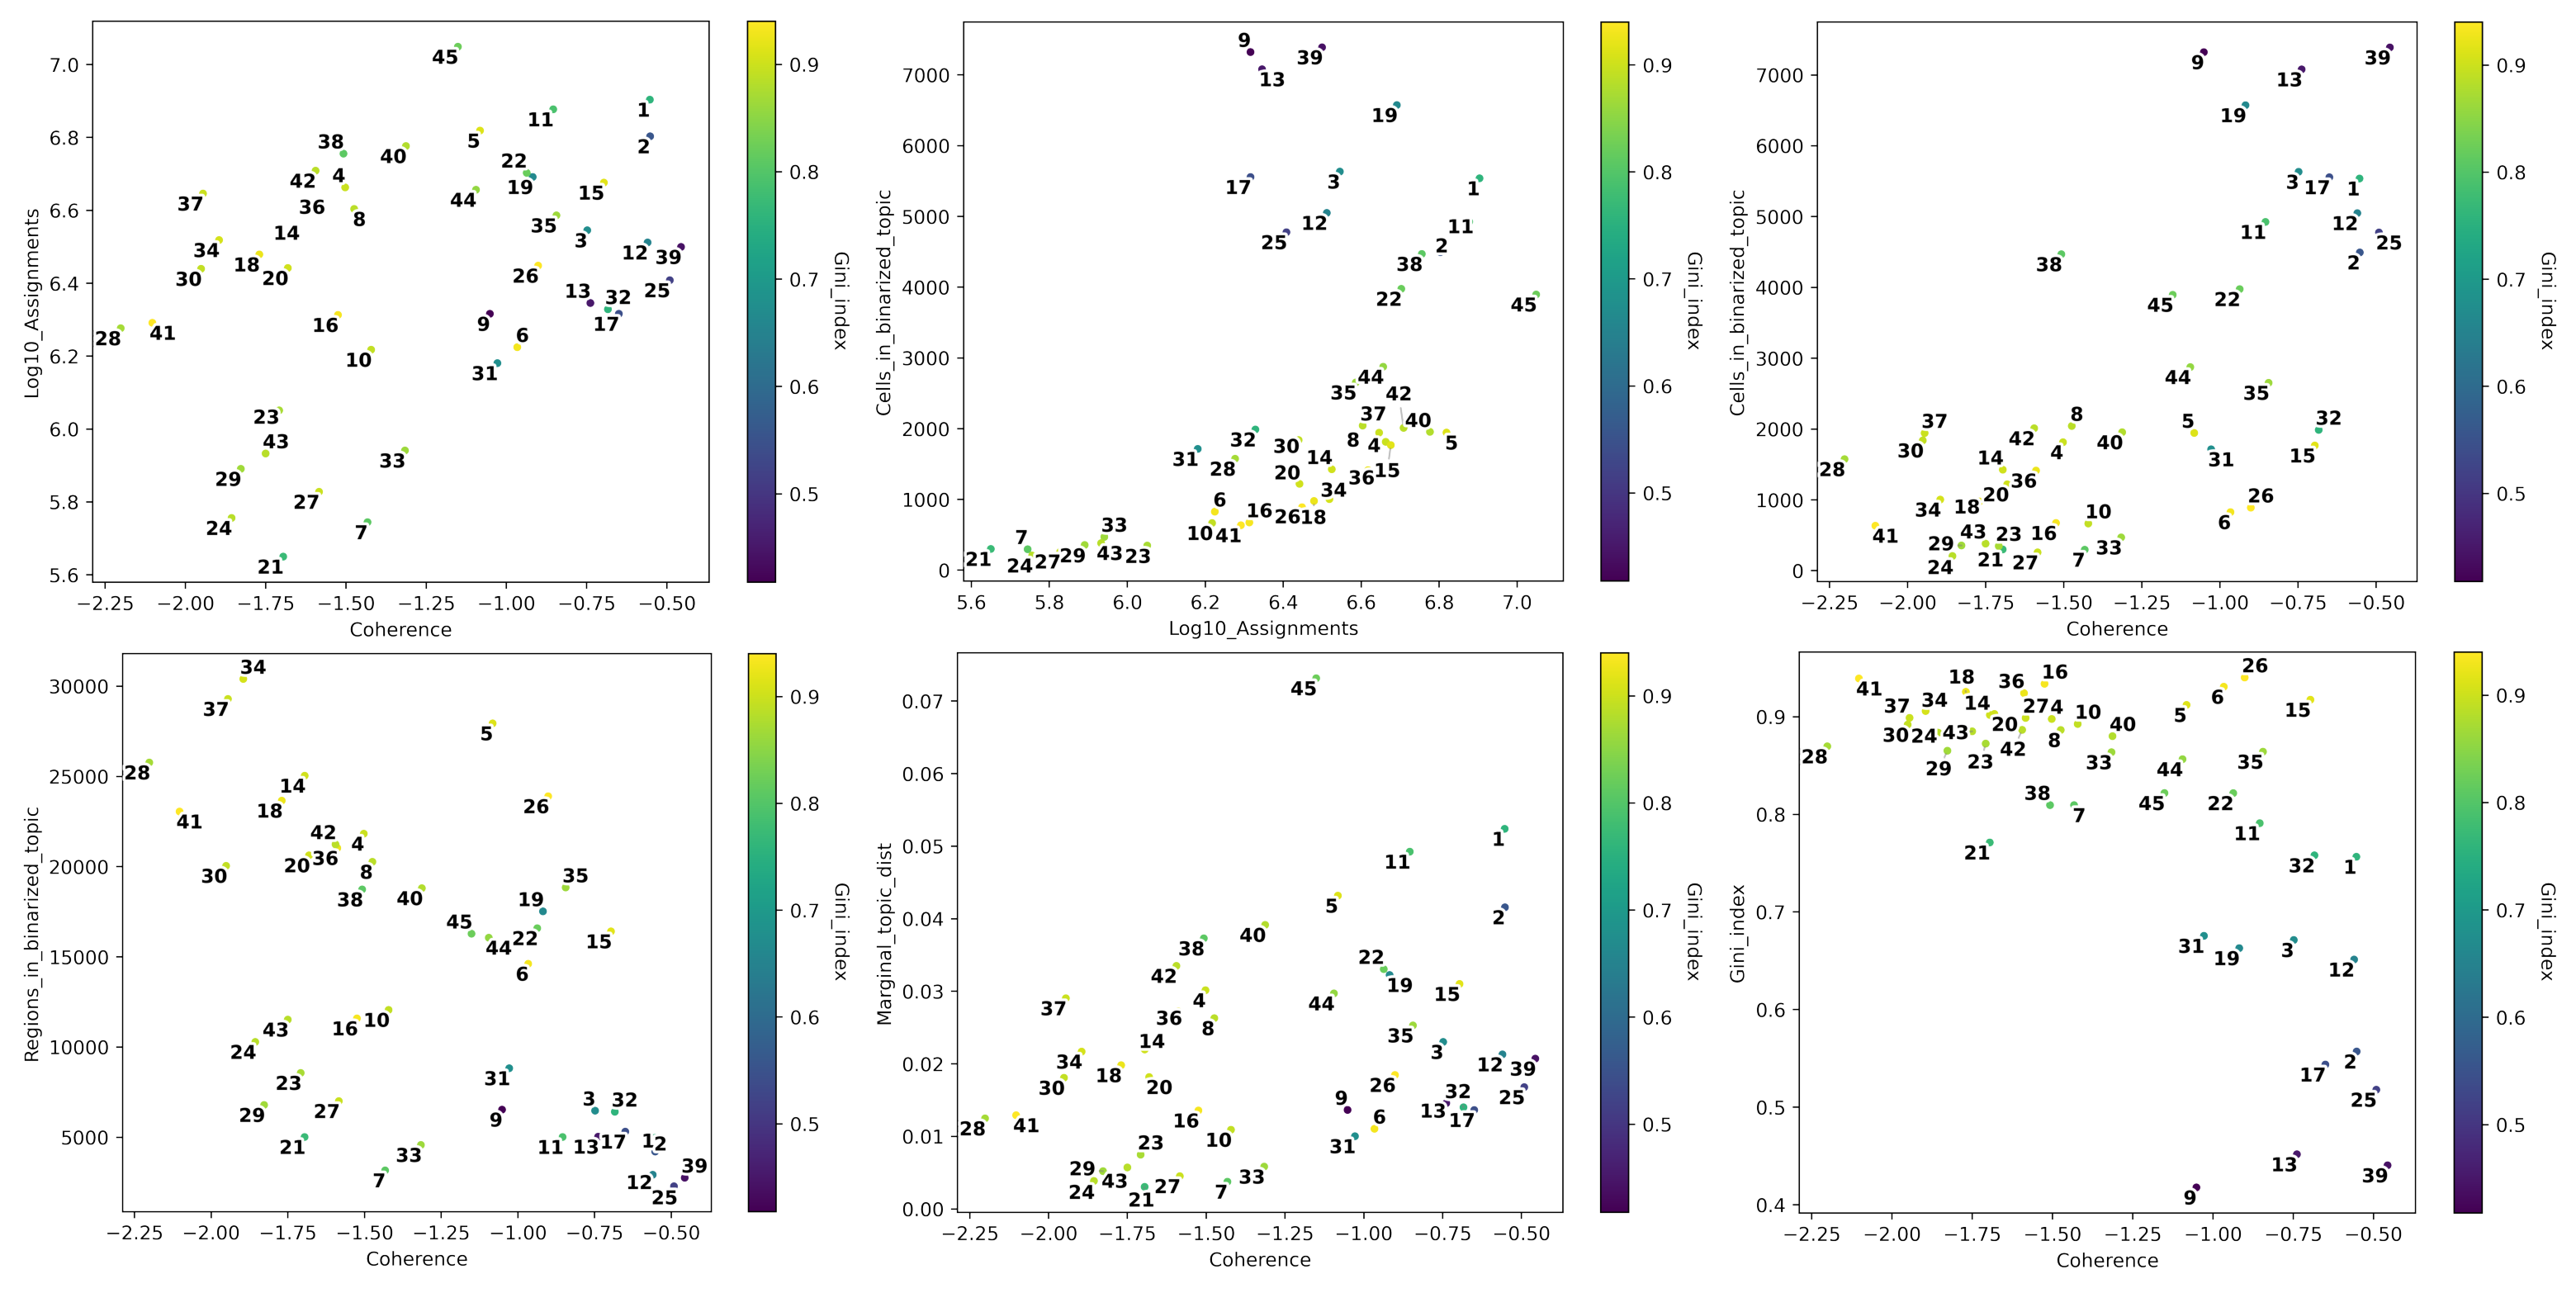

In [26]:
from pycisTopic.topic_qc import compute_topic_metrics, plot_topic_qc, topic_annotation
import matplotlib.pyplot as plt
from pycisTopic.utils import fig2img 


topic_qc_metrics = compute_topic_metrics(cistopic_obj)
fig_dict={}
fig_dict['CoherenceVSAssignments']=plot_topic_qc(topic_qc_metrics, var_x='Coherence', var_y='Log10_Assignments', var_color='Gini_index', plot=False, return_fig=True)
fig_dict['AssignmentsVSCells_in_bin']=plot_topic_qc(topic_qc_metrics, var_x='Log10_Assignments', var_y='Cells_in_binarized_topic', var_color='Gini_index', plot=False, return_fig=True)
fig_dict['CoherenceVSCells_in_bin']=plot_topic_qc(topic_qc_metrics, var_x='Coherence', var_y='Cells_in_binarized_topic', var_color='Gini_index', plot=False, return_fig=True)
fig_dict['CoherenceVSRegions_in_bin']=plot_topic_qc(topic_qc_metrics, var_x='Coherence', var_y='Regions_in_binarized_topic', var_color='Gini_index', plot=False, return_fig=True)
fig_dict['CoherenceVSMarginal_dist']=plot_topic_qc(topic_qc_metrics, var_x='Coherence', var_y='Marginal_topic_dist', var_color='Gini_index', plot=False, return_fig=True)
fig_dict['CoherenceVSGini_index']=plot_topic_qc(topic_qc_metrics, var_x='Coherence', var_y='Gini_index', var_color='Gini_index', plot=False, return_fig=True)

# Plot topic stats in one figure
fig=plt.figure(figsize=(40, 43))
i = 1
for fig_ in fig_dict.keys():
    plt.subplot(2, 3, i)
    img = fig2img(fig_dict[fig_]) #To convert figures to png to plot together, see .utils.py. This converts the figure to png.
    plt.imshow(img)
    plt.axis('off')
    i += 1
plt.subplots_adjust(wspace=0, hspace=-0.70)
plt.show()

In [27]:
topic_annot = topic_annotation(
    cistopic_obj,
    annot_var='leiden',
    binarized_cell_topic=binarized_cell_topic,
    general_topic_thr = 0.2
)

topic_annot

/home/rsun@ZHANGroup.local/anaconda3/envs/scenicplus/lib/python3.11/site-packages/statsmodels/stats/weightstats.py:792: RuntimeWarning: divide by zero encountered in scalar divide
  zstat = value / std


,leiden,Ratio_cells_in_topic,Ratio_group_in_population,is_general
Topic1,"0, 3, 9, 10",0.285332,0.446958,False
Topic2,"5, 3, 7, 9, 8, 10",0.231542,0.314854,False
Topic3,"7, 1, 8, 4, 6",0.290226,0.376372,False
Topic4,"4, 2",0.093462,0.200216,False
Topic5,"5, 3, 9, 10",0.100211,0.202999,False
Topic6,"5, 3, 7, 10",0.042609,0.232109,False
Topic7,"7, 9, 8",0.015251,0.142048,False
Topic8,"1, 2, 6",0.10526,0.302849,False
Topic9,"5, 3, 1, 8, 10",0.377248,0.355763,False
Topic10,"7, 8",0.034314,0.111855,False


In [28]:
topic_annot = topic_annotation(
    cistopic_obj,
    annot_var='species',
    binarized_cell_topic=binarized_cell_topic,
    general_topic_thr = 0.2
)

topic_annot

/home/rsun@ZHANGroup.local/anaconda3/envs/scenicplus/lib/python3.11/site-packages/statsmodels/stats/weightstats.py:792: RuntimeWarning: divide by zero encountered in scalar divide
  zstat = value / std


,species,Ratio_cells_in_topic,Ratio_group_in_population,is_general
Topic1,T,0.285332,0.28765,False
Topic2,"QF, M",0.231542,0.202947,False
Topic3,"CY, JT",0.290226,0.509403,False
Topic4,CY,0.093462,0.254573,False
Topic5,M,0.100211,0.110258,False
Topic6,QF,0.042609,0.092689,False
Topic7,"CY, QF",0.015251,0.347262,False
Topic8,CY,0.10526,0.254573,False
Topic9,"QF, M",0.377248,0.202947,False
Topic10,JT,0.034314,0.25483,False


## DARs

2025-06-19 08:53:42,092 cisTopic     INFO     Imputing region accessibility
2025-06-19 08:53:42,093 cisTopic     INFO     Impute region accessibility for regions 0-20000
2025-06-19 08:53:43,550 cisTopic     INFO     Impute region accessibility for regions 20000-40000
2025-06-19 08:53:46,204 cisTopic     INFO     Impute region accessibility for regions 40000-60000
2025-06-19 08:53:48,203 cisTopic     INFO     Impute region accessibility for regions 60000-80000
2025-06-19 08:53:50,128 cisTopic     INFO     Impute region accessibility for regions 80000-100000
2025-06-19 08:53:51,758 cisTopic     INFO     Impute region accessibility for regions 100000-120000
2025-06-19 08:53:53,281 cisTopic     INFO     Impute region accessibility for regions 120000-140000
2025-06-19 08:53:54,823 cisTopic     INFO     Impute region accessibility for regions 140000-160000
2025-06-19 08:53:56,281 cisTopic     INFO     Impute region accessibility for regions 160000-180000
2025-06-19 08:53:57,793 cisTopic     

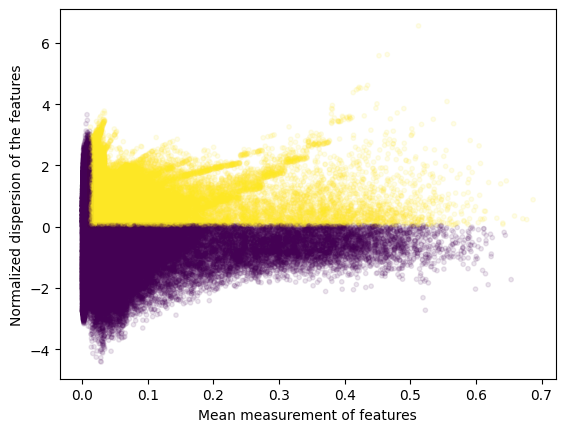

2025-06-19 09:04:17,982 cisTopic     INFO     Done!


In [29]:
from pycisTopic.diff_features import (
    impute_accessibility,
    normalize_scores,
    find_highly_variable_features,
    find_diff_features
)
import numpy as np

imputed_acc_obj = impute_accessibility(
    cistopic_obj,
    selected_cells=None,
    selected_regions=None,
    scale_factor=10**6
)

normalized_imputed_acc_obj = normalize_scores(imputed_acc_obj, scale_factor=10**4)

variable_regions = find_highly_variable_features(
    normalized_imputed_acc_obj,
    min_disp = 0.05,
    min_mean = 0.0125,
    max_mean = 3,
    max_disp = np.inf,
    n_bins=20,
    n_top_features=None,
    plot=True
)

In [30]:
print(len(variable_regions))

markers_dict= find_diff_features(
    cistopic_obj,
    imputed_acc_obj,
    variable='leiden',
    var_features=variable_regions,
    contrasts=None,
    adjpval_thr=0.05,
    log2fc_thr=np.log2(1.5),
    n_cpu=5,
    _temp_dir=None,
    split_pattern = '-'
)

72442


2025-06-19 09:04:41,129	INFO worker.py:1724 -- Started a local Ray instance.


2025-06-19 09:04:41,474 cisTopic     INFO     Subsetting data for 0 (5849 of 19409)
2025-06-19 09:04:47,694 cisTopic     INFO     Computing p-value for 0


(get_wilcox_test_pvalues_ray pid=1532958) /home/rsun@ZHANGroup.local/anaconda3/envs/scenicplus/lib/python3.11/site-packages/ray/_private/pydantic_compat.py:2: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
(get_wilcox_test_pvalues_ray pid=1532958)   from pkg_resources import packaging


2025-06-19 09:05:04,976 cisTopic     INFO     Computing log2FC for 0
2025-06-19 09:05:09,315 cisTopic     INFO     0 done!
2025-06-19 09:05:09,323 cisTopic     INFO     Subsetting data for 1 (2531 of 19409)
2025-06-19 09:05:09,728 cisTopic     INFO     Computing p-value for 1
2025-06-19 09:05:24,676 cisTopic     INFO     Computing log2FC for 1
2025-06-19 09:05:24,771 cisTopic     INFO     1 done!
2025-06-19 09:05:25,602 cisTopic     INFO     Subsetting data for 10 (494 of 19409)
2025-06-19 09:05:26,002 cisTopic     INFO     Computing p-value for 10
2025-06-19 09:05:40,887 cisTopic     INFO     Computing log2FC for 10
2025-06-19 09:05:40,974 cisTopic     INFO     10 done!
2025-06-19 09:05:41,674 cisTopic     INFO     Subsetting data for 2 (2315 of 19409)
2025-06-19 09:05:42,078 cisTopic     INFO     Computing p-value for 2
2025-06-19 09:05:56,906 cisTopic     INFO     Computing log2FC for 2
2025-06-19 09:05:56,996 cisTopic     INFO     2 done!
2025-06-19 09:05:57,728 cisTopic     INFO  

(get_wilcox_test_pvalues_ray pid=1532960) /home/rsun@ZHANGroup.local/anaconda3/envs/scenicplus/lib/python3.11/site-packages/ray/_private/pydantic_compat.py:2: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81. [repeated 4x across cluster] (Ray deduplicates logs by default. Set RAY_DEDUP_LOGS=0 to disable log deduplication, or see https://docs.ray.io/en/master/ray-observability/ray-logging.html#log-deduplication for more options.)
(get_wilcox_test_pvalues_ray pid=1532960)   from pkg_resources import packaging [repeated 4x across cluster]


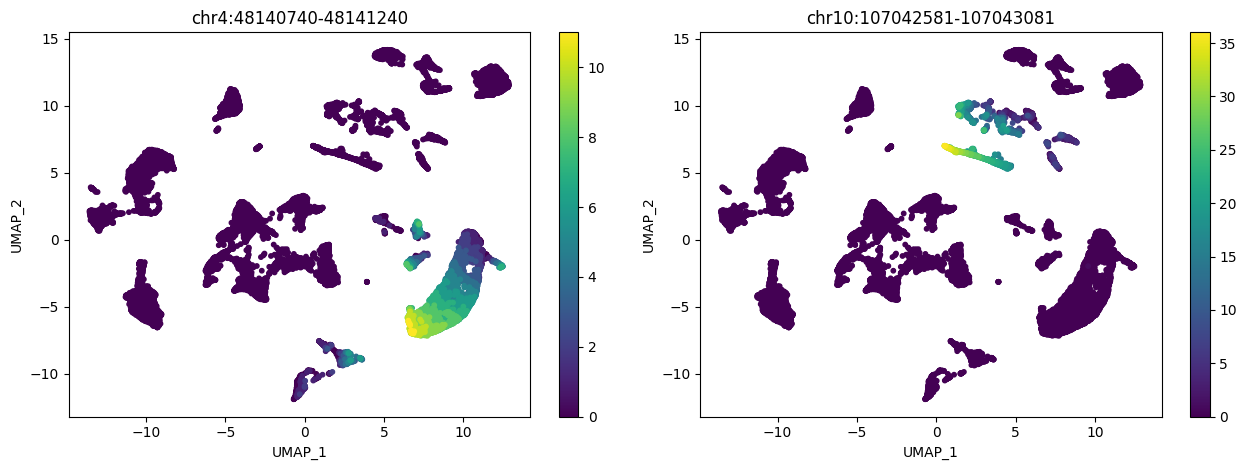

Number of DARs found:
---------------------
  0: 19059
  1: 15454
  10: 18282
  2: 25723
  3: 17299
  4: 23893
  5: 14782
  6: 17602
  7: 4106
  8: 8062
  9: 12240


In [31]:
from pycisTopic.clust_vis import plot_imputed_features
plot_imputed_features(
    cistopic_obj,
    reduction_name='UMAP',
    imputed_data=imputed_acc_obj,
    features=[markers_dict[x].index.tolist()[0] for x in ['0','5']],
    scale=False,
    num_columns=4
)

print("Number of DARs found:")
print("---------------------")
for x in markers_dict:
    print(f"  {x}: {len(markers_dict[x])}")

## save region sets

In [32]:
os.makedirs(os.path.join(out_dir, "region_sets"), exist_ok = True)
os.makedirs(os.path.join(out_dir, "region_sets", "Topics_otsu"), exist_ok = True)
os.makedirs(os.path.join(out_dir, "region_sets", "Topics_top_3k"), exist_ok = True)
os.makedirs(os.path.join(out_dir, "region_sets", "DARs_cell_type"), exist_ok = True)
from pycisTopic.utils import region_names_to_coordinates

for topic in region_bin_topics_otsu:
    region_names_to_coordinates(
        region_bin_topics_otsu[topic].index
    ).sort_values(
        ["Chromosome", "Start", "End"]
    ).to_csv(
        os.path.join(out_dir, "region_sets", "Topics_otsu", f"{topic}.bed"),
        sep = "\t",
        header = False, index = False
    )

for topic in region_bin_topics_top_3k:
    region_names_to_coordinates(
        region_bin_topics_top_3k[topic].index
    ).sort_values(
        ["Chromosome", "Start", "End"]
    ).to_csv(
        os.path.join(out_dir, "region_sets", "Topics_top_3k", f"{topic}.bed"),
        sep = "\t",
        header = False, index = False
    )

for cell_type in markers_dict:
    region_names_to_coordinates(
        markers_dict[cell_type].index
    ).sort_values(
        ["Chromosome", "Start", "End"]
    ).to_csv(
        os.path.join(out_dir, "region_sets", "DARs_cell_type", f"{cell_type}.bed"),
        sep = "\t",
        header = False, index = False
    )

In [33]:
import pickle
pickle.dump(
    cistopic_obj,
    open(os.path.join(out_dir, "cistopic_obj.pkl"), "wb")
)